# 🌲 Huấn Luyện Các Biến Thể PSO Tối Ưu Siêu Tham Số Mạng Nơ-ron (MLP) - Bộ Dữ Liệu Forest Covertype

Notebook này tập trung vào giai đoạn **khám phá, trực quan hóa và tiền xử lý dữ liệu** trước khi áp dụng các biến thể **PSO (Particle Swarm Optimization)** để tối ưu hóa siêu tham số cho mạng nơ-ron đa tầng (`MLPClassifier`).

### 📌 Nội dung thực hiện:
1. **Khám phá dữ liệu thô**: Tải toàn bộ 581,012 mẫu của bộ dữ liệu Forest Covertype.
2. **Biểu đồ 1 (Histogram / Biểu đồ cột)**: Phân phối số lượng mẫu của từng lớp khi chưa chia Train/Test.
3. **Tiền xử lý dữ liệu**: Lấy mẫu phân tầng và chia tập Train/Test theo tỷ lệ phân tầng 80/20.
4. **Biểu đồ 2 (Biểu đồ chia Train/Test)**: Phân bố số lượng mẫu cụ thể của từng lớp trong tập Train và tập Test.

## 📦 1. Cài đặt và Khai báo Thư viện

In [15]:
import sys
if sys.stdout and hasattr(sys.stdout, "reconfigure"):
    try:
        sys.stdout.reconfigure(encoding="utf-8")
    except Exception:
        pass
import os
import time
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("✅ Khai báo thư viện thành công!")

✅ Khai báo thư viện thành công!


## 📊 2. Tải và Khám Phá Dữ Liệu Thô (Forest Covertype Data)

In [16]:
# Định nghĩa đầy đủ danh sách 55 tên cột
CONTINUOUS_COLS = [
    'Elevation', 'Aspect', 'Slope',
    'Horizontal_Distance_To_Hydrology', 'Vertical_Distance_To_Hydrology',
    'Horizontal_Distance_To_Roadways',
    'Hillshade_9am', 'Hillshade_Noon', 'Hillshade_3pm',
    'Horizontal_Distance_To_Fire_Points'
]
WILDERNESS_COLS = [f'Wilderness_Area_{i}' for i in range(1, 5)]
SOIL_COLS = [f'Soil_Type_{i}' for i in range(1, 41)]
ALL_FEATURE_COLS = CONTINUOUS_COLS + WILDERNESS_COLS + SOIL_COLS
TARGET_COL = 'Cover_Type'
COL_NAMES = ALL_FEATURE_COLS + [TARGET_COL]

# Tên mô tả của 7 loại cây che phủ rừng
COVER_TYPE_NAMES = {
    1: 'Spruce/Fir',
    2: 'Lodgepole Pine',
    3: 'Ponderosa Pine',
    4: 'Cottonwood/Willow',
    5: 'Aspen',
    6: 'Douglas-fir',
    7: 'Krummholz'
}

# Tải file dữ liệu covtype.data
data_path = '../data/raw/covertype/covtype.data'
if not os.path.exists(data_path):
    data_path = 'data/raw/covertype/covtype.data'

print(f"🔄 Đang tải dữ liệu từ {data_path}...")
t0 = time.time()
df = pd.read_csv(data_path, header=None, names=COL_NAMES)
print(f"✅ Tải thành công trong {time.time() - t0:.2f}s!")

df['Cover_Type_Name'] = df['Cover_Type'].map(COVER_TYPE_NAMES)

print("=" * 65)
print("        THÔNG TIN TỔNG QUAN BỘ DỮ LIỆU FOREST COVERTYPE")
print("=" * 65)
print(f"  Tổng số mẫu quan sát (Rows)   : {df.shape[0]:,}")
print(f"  Tổng số cột (Columns)         : {df.shape[1]}")
print(f"  Số đặc trưng số liên tục      : {len(CONTINUOUS_COLS)}")
print(f"  Số đặc trưng Wilderness Area  : {len(WILDERNESS_COLS)}")
print(f"  Số đặc trưng Soil Type        : {len(SOIL_COLS)}")
print(f"  Số lớp phân loại mục tiêu     : {df['Cover_Type'].nunique()} (Lớp 1 đến 7)")
print(f"  Số giá trị rỗng (Missing)     : {df.isnull().sum().sum()}")
print("=" * 65)

🔄 Đang tải dữ liệu từ ../data/raw/covertype/covtype.data...
✅ Tải thành công trong 1.48s!
        THÔNG TIN TỔNG QUAN BỘ DỮ LIỆU FOREST COVERTYPE
  Tổng số mẫu quan sát (Rows)   : 581,012
  Tổng số cột (Columns)         : 56
  Số đặc trưng số liên tục      : 10
  Số đặc trưng Wilderness Area  : 4
  Số đặc trưng Soil Type        : 40
  Số lớp phân loại mục tiêu     : 7 (Lớp 1 đến 7)
  Số giá trị rỗng (Missing)     : 0


## 📈 3. Biểu Đồ 1: Histogram (Biểu Đồ Cột) Phân Phối Số Lượng Mẫu Của Từng Lớp
Biểu đồ hiển thị chính xác số lượng mẫu và tỷ lệ phần trăm của từng lớp trên toàn bộ 581,012 mẫu dữ liệu gốc khi chưa phân chia Train/Test.

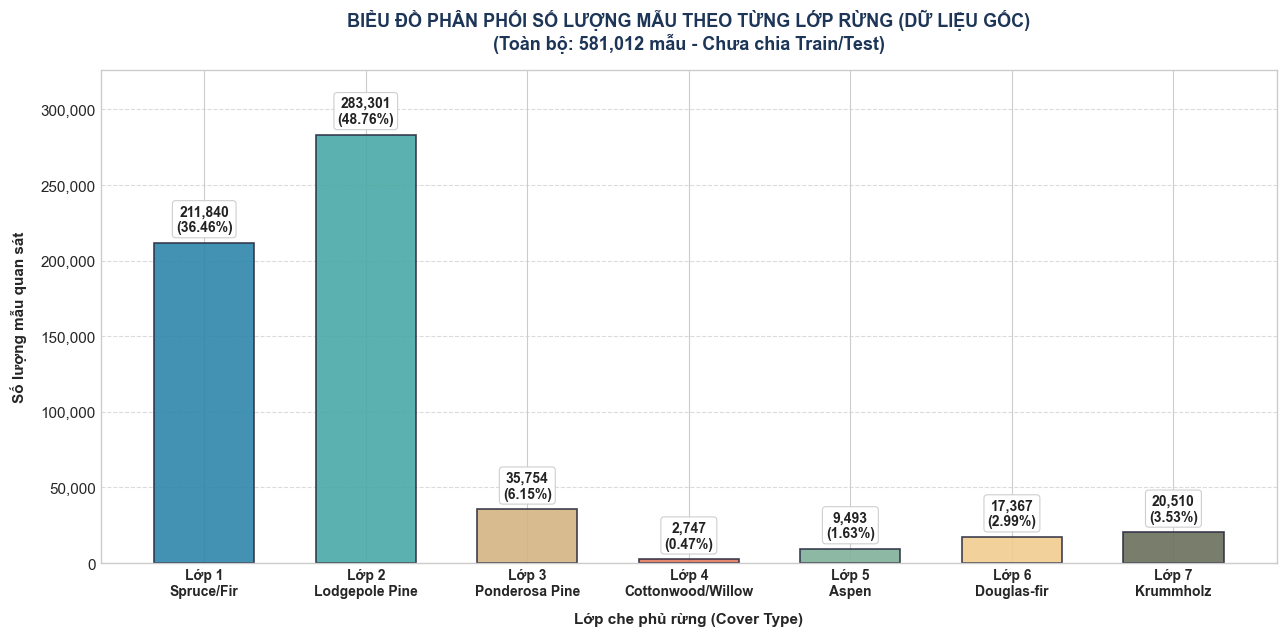

In [17]:
# BIỂU ĐỒ 1: Biểu đồ cột (Histogram) phân phối số lượng mẫu của từng lớp
counts = df['Cover_Type'].value_counts().sort_index()
total_samples = len(df)

plt.figure(figsize=(13, 6.5), dpi=100)
colors = ['#2E86AB', '#48A9A6', '#D4B483', '#E07A5F', '#81B29A', '#F2CC8F', '#6B705C']

bars = plt.bar(
    range(1, 8),
    counts.values,
    color=colors,
    edgecolor='#2b2d42',
    linewidth=1.2,
    width=0.62,
    alpha=0.9
)

title_text = (
    'BIỂU ĐỒ PHÂN PHỐI SỐ LƯỢNG MẪU THEO TỪNG LỚP RỪNG (DỮ LIỆU GỐC)\n'
    '(Toàn bộ: 581,012 mẫu - Chưa chia Train/Test)'
)
plt.title(title_text, fontsize=13, fontweight='bold', pad=15, color='#1d3557')
plt.xlabel('Lớp che phủ rừng (Cover Type)', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Số lượng mẫu quan sát', fontsize=11, fontweight='bold', labelpad=10)
labels = [f'Lớp {i}\n' + COVER_TYPE_NAMES[i] for i in range(1, 8)]
plt.xticks(range(1, 8), labels, fontsize=10, fontweight='bold')
plt.ylim(0, max(counts.values) * 1.15)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))

# Hiển thị số lượng mẫu và % trên đỉnh mỗi cột
for bar in bars:
    h = bar.get_height()
    pct = (h / total_samples) * 100
    label = f'{h:,}\n({pct:.2f}%)'
    plt.annotate(
        label,
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 6),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=10,
        fontweight='bold',
        color='#222222',
        bbox=dict(boxstyle='round,pad=0.25', facecolor='#ffffff', edgecolor='#cccccc', alpha=0.95, linewidth=0.8)
    )

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## ⚙️ 4. Tiền Xử Lý Dữ Liệu & Phân Chia Train / Test

In [18]:
# 1. Cấu hình lấy mẫu đại diện phân tầng (Stratified Sampling)
USE_SAMPLE = True
SAMPLE_SIZE = 30000  # Đặt None hoặc False nếu muốn chạy toàn bộ 581,012 dòng

if USE_SAMPLE and SAMPLE_SIZE is not None and SAMPLE_SIZE < len(df):
    print(f"⚡ Đang lấy mẫu phân tầng {SAMPLE_SIZE:,} dòng từ {len(df):,} dòng gốc...")
    working_df, _ = train_test_split(
        df, train_size=SAMPLE_SIZE, stratify=df[TARGET_COL], random_state=RANDOM_SEED
    )
else:
    print(f"📊 Sử dụng toàn bộ {len(df):,} mẫu dữ liệu...")
    working_df = df

# 2. Tách đặc trưng X và nhãn mục tiêu y (chuẩn hóa nhãn về 0-indexed: 0 -> 6)
X = working_df[ALL_FEATURE_COLS].values
y = (working_df[TARGET_COL].values - 1).astype(int)

# 3. Phân chia tập Train (80%) và Test (20%) phân tầng
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_SEED, stratify=y
)

# 4. Chuẩn hóa đặc trưng bằng StandardScaler
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc  = scaler.transform(X_test)

print("=" * 65)
print("        KẾT QUẢ TIỀN XỬ LÝ DỮ LIỆU HOÀN TẤT")
print("=" * 65)
print(f"  Tập Train       : {X_train_sc.shape[0]:,} mẫu | Shape: {X_train_sc.shape}")
print(f"  Tập Test        : {X_test_sc.shape[0]:,} mẫu  | Shape: {X_test_sc.shape}")
print(f"  Số đặc trưng    : {X_train_sc.shape[1]} (toàn bộ 54 đặc trưng đã được chuẩn hóa)")
print(f"  Nhãn mục tiêu   : {np.unique(y_train)} (7 lớp tương ứng 0 đến 6)")
print(f"  Tỷ lệ phân tầng : Giữ nguyên tuyệt đối tỷ lệ các lớp")
print("=" * 65)

⚡ Đang lấy mẫu phân tầng 30,000 dòng từ 581,012 dòng gốc...
        KẾT QUẢ TIỀN XỬ LÝ DỮ LIỆU HOÀN TẤT
  Tập Train       : 24,000 mẫu | Shape: (24000, 54)
  Tập Test        : 6,000 mẫu  | Shape: (6000, 54)
  Số đặc trưng    : 54 (toàn bộ 54 đặc trưng đã được chuẩn hóa)
  Nhãn mục tiêu   : [0 1 2 3 4 5 6] (7 lớp tương ứng 0 đến 6)
  Tỷ lệ phân tầng : Giữ nguyên tuyệt đối tỷ lệ các lớp


## 📊 5. Biểu Đồ 2: Biểu Đồ Chia Train / Test Của Từng Lớp
Biểu đồ cột nhóm (Grouped Bar Chart) so sánh trực quan số lượng mẫu và tỷ lệ của từng lớp giữa tập Train và tập Test sau khi phân chia phân tầng (Stratified Split).

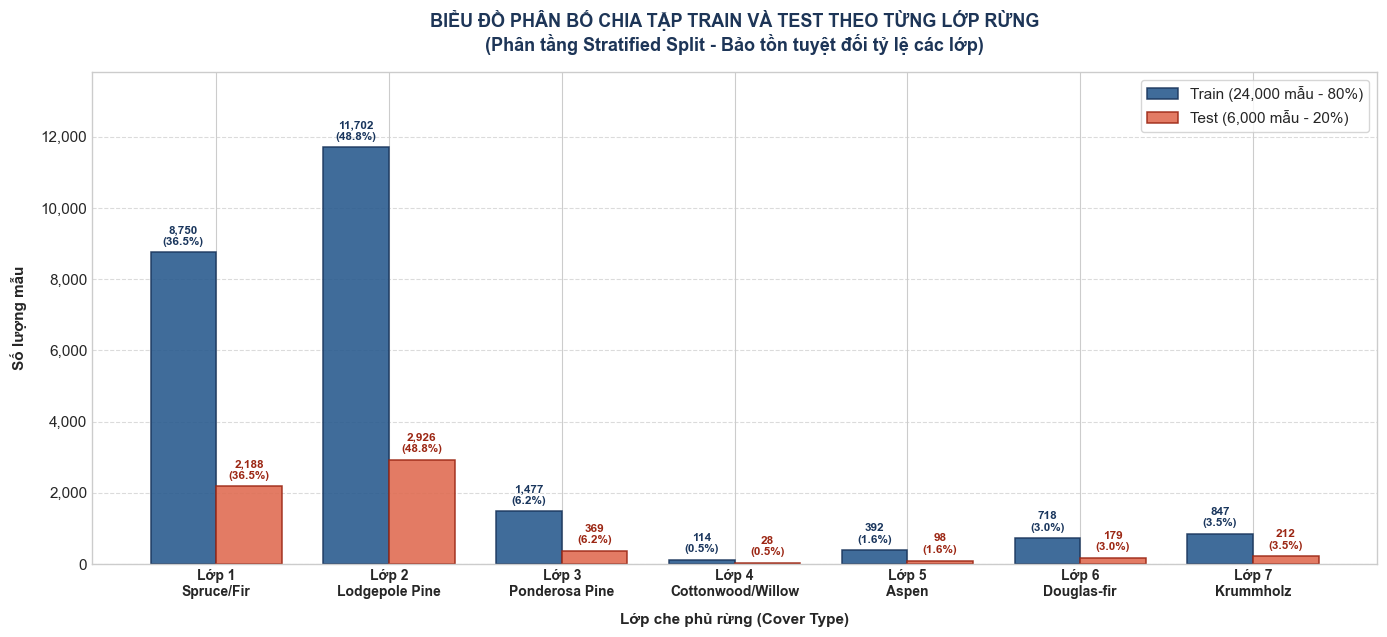

In [19]:
# BIỂU ĐỒ 2: Biểu đồ so sánh phân bổ chia Train / Test của từng lớp
train_counts = pd.Series(y_train).value_counts().sort_index()
test_counts = pd.Series(y_test).value_counts().sort_index()

x_indices = np.arange(1, 8)
width = 0.38

plt.figure(figsize=(14, 6.5), dpi=100)
bars_train = plt.bar(
    x_indices - width/2,
    train_counts.values,
    width=width,
    label=f'Train ({len(y_train):,} mẫu - 80%)',
    color='#2B5C8F',
    edgecolor='#1a365d',
    linewidth=1.1,
    alpha=0.9
)
bars_test = plt.bar(
    x_indices + width/2,
    test_counts.values,
    width=width,
    label=f'Test ({len(y_test):,} mẫu - 20%)',
    color='#E06D53',
    edgecolor='#9c2714',
    linewidth=1.1,
    alpha=0.9
)

title_text = (
    'BIỂU ĐỒ PHÂN BỐ CHIA TẬP TRAIN VÀ TEST THEO TỪNG LỚP RỪNG\n'
    '(Phân tầng Stratified Split - Bảo tồn tuyệt đối tỷ lệ các lớp)'
)
plt.title(title_text, fontsize=13, fontweight='bold', pad=15, color='#1d3557')
plt.xlabel('Lớp che phủ rừng (Cover Type)', fontsize=11, fontweight='bold', labelpad=10)
plt.ylabel('Số lượng mẫu', fontsize=11, fontweight='bold', labelpad=10)
labels = [f'Lớp {i}\n' + COVER_TYPE_NAMES[i] for i in range(1, 8)]
plt.xticks(x_indices, labels, fontsize=10, fontweight='bold')
plt.ylim(0, max(train_counts.values) * 1.18)
plt.gca().yaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f'{int(x):,}'))

# Hiển thị số lượng mẫu trên đỉnh mỗi cột Train
for bar in bars_train:
    h = bar.get_height()
    pct = (h / len(y_train)) * 100
    plt.annotate(
        f'{h:,}\n({pct:.1f}%)',
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center', va='bottom',
        fontsize=8.5,
        fontweight='bold',
        color='#1a365d'
    )

# Hiển thị số lượng mẫu trên đỉnh mỗi cột Test
for bar in bars_test:
    h = bar.get_height()
    pct = (h / len(y_test)) * 100
    plt.annotate(
        f'{h:,}\n({pct:.1f}%)',
        xy=(bar.get_x() + bar.get_width() / 2, h),
        xytext=(0, 4),
        textcoords='offset points',
        ha='center', va='bottom',
        fontsize=8.5,
        fontweight='bold',
        color='#9c2714'
    )

plt.legend(frameon=True, fontsize=11, loc='upper right')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## 🔧 6. Định nghĩa Không gian tìm kiếm 3D & Hàm Fitness


In [20]:
LOW  = np.array([16,  -4.0, -5.0])
HIGH = np.array([256, -1.0, -1.0])
DIM  = 3

def decode_position(x):
    """
    Giải mã vị trí hạt 3D thành siêu tham số mạng nơ-ron MLP:
    - x[0]: n_neurons (số neuron mỗi hidden layer, nguyên từ 16 đến 256)
    - x[1]: log10(lr) (tốc độ học learning rate từ 10^-4 đến 10^-1)
    - x[2]: log10(alpha) (hệ số điều chuẩn L2 regularization từ 10^-5 đến 10^-1)
    """
    n_neurons = int(np.clip(round(x[0]), 16, 256))
    lr        = float(10 ** np.clip(x[1], -4.0, -1.0))
    alpha     = float(10 ** np.clip(x[2], -5.0, -1.0))
    return n_neurons, lr, alpha

def fitness_single(x, X_tr, y_tr, cv_obj, seed):
    """
    Hàm tính fitness: Đánh giá 5-fold Stratified Cross-Validation Accuracy trên tập Train.
    """
    n_neurons, lr, alpha = decode_position(x)
    model = MLPClassifier(
        hidden_layer_sizes=(n_neurons, n_neurons),
        activation='relu',
        learning_rate_init=lr,
        alpha=alpha,
        max_iter=500,
        random_state=seed,
        early_stopping=True,
        n_iter_no_change=15
    )
    scores = cross_val_score(model, X_tr, y_tr, cv=cv_obj,
                             scoring='accuracy', n_jobs=-1)
    return scores.mean()

def fitness_averaged(x, X_tr, y_tr, cv_obj, seed, k=3):
    """
    Hàm tính fitness trung bình qua k lần chạy với các seed ngẫu nhiên khác nhau để giảm thiểu nhiễu.
    """
    scores_all = []
    for run in range(k):
        n_neurons, lr, alpha = decode_position(x)
        model = MLPClassifier(
            hidden_layer_sizes=(n_neurons, n_neurons),
            activation='relu',
            learning_rate_init=lr,
            alpha=alpha,
            max_iter=500,
            random_state=seed + run, 
            early_stopping=True,
            n_iter_no_change=15
        )
        s = cross_val_score(model, X_tr, y_tr, cv=cv_obj,
                            scoring='accuracy', n_jobs=-1)
        scores_all.append(s.mean())
    return np.mean(scores_all)

print(' Không gian tìm kiếm siêu tham số (3 chiều):')
print(f'   x[0] = n_neurons    ∈ [16, 256]    (Số neuron mỗi hidden layer)')
print(f'   x[1] = log10(lr)    ∈ [-4, -1]  →  lr    ∈ [0.0001, 0.1]')
print(f'   x[2] = log10(alpha) ∈ [-5, -1]  →  alpha ∈ [0.00001, 0.1]')


 Không gian tìm kiếm siêu tham số (3 chiều):
   x[0] = n_neurons    ∈ [16, 256]    (Số neuron mỗi hidden layer)
   x[1] = log10(lr)    ∈ [-4, -1]  →  lr    ∈ [0.0001, 0.1]
   x[2] = log10(alpha) ∈ [-5, -1]  →  alpha ∈ [0.00001, 0.1]


## 🔵 1. Thuật toán PSO gốc (Standard PSO)
- **Cơ chế:** Vận tốc và vị trí chuẩn của Kennedy & Eberhart (1995) với quán tính $w = 0.7$, hệ số gia tốc $c_1 = c_2 = 1.5$.
- **Không gian 3D:** $x = [\text{n\_neurons}, \log_{10}(\text{lr}), \log_{10}(\alpha)]$.
- **Mục tiêu:** Tối đa hóa 5-fold CV Accuracy trên tập Train.
- **Siêu tham số thực nghiệm:** $N = 12$ hạt, $T = 20$ vòng lặp, $v_{\max} = 0.2 \times (\text{HIGH} - \text{LOW})$, seed = 42.


In [21]:
def run_standard_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.7,       
    n1=1.5,      
    n2=1.5,      
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🔵 Standard PSO | w={w} (cố định) | n1={n1}, n2={n2}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*65)
    t_start = time.time()

    for it in range(n_iter):
        t_iter_start = time.time()
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w  * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n:3d}, lr={lr:.5f}, alpha={al:.6f} | [vòng: {time.time()-t_iter_start:.1f}s, tổng: {time.time()-t_start:.0f}s]')

    print('─'*65)
    print(f'✅ Hoàn thành huấn luyện! Tổng thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


# Chạy huấn luyện Standard PSO
gbest_std, cv_std, conv_std, hist_std = run_standard_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w=0.7, n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)
n_std, lr_std, al_std = decode_position(gbest_std)
print(f'\n🏆 KẾT QUẢ TỐI ƯU STANDARD PSO:')
print(f'  Best Params : neurons={n_std}, lr={lr_std:.5f}, alpha={al_std:.6f}')
print(f'  CV Accuracy : {cv_std:.4f}')


🔵 Standard PSO | w=0.7 (cố định) | n1=1.5, n2=1.5
   12 particles × 20 iterations
─────────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [vòng: 282.2s, tổng: 282s]
  Iter  2/20 | gbest=0.8368 | neurons=189, lr=0.00203, alpha=0.019119 | [vòng: 337.9s, tổng: 620s]
  Iter  3/20 | gbest=0.8408 | neurons=225, lr=0.00185, alpha=0.001522 | [vòng: 302.7s, tổng: 923s]
  Iter  4/20 | gbest=0.8408 | neurons=225, lr=0.00185, alpha=0.001522 | [vòng: 414.6s, tổng: 1337s]
  Iter  5/20 | gbest=0.8408 | neurons=225, lr=0.00185, alpha=0.001522 | [vòng: 512.8s, tổng: 1850s]
  Iter  6/20 | gbest=0.8408 | neurons=225, lr=0.00185, alpha=0.001522 | [vòng: 406.5s, tổng: 2257s]
  Iter  7/20 | gbest=0.8408 | neurons=225, lr=0.00185, alpha=0.001522 | [vòng: 474.3s, tổng: 2731s]
  Iter  8/20 | gbest=0.8408 | neurons=225, lr=0.00185, alpha=0.001522 | [vòng: 554.9s, tổng: 3286s]
  Iter  9/20 | gbest=0.8408 | neurons=225, lr=0.00185, 

In [24]:
import joblib, os

# Tạo thư mục checkpoints nếu chưa tồn tại
os.makedirs('../results/checkpoints', exist_ok=True)

# Lưu đầy đủ trạng thái tối ưu
joblib.dump({
    'gbest_pos':   gbest_std,
    'cv_score':    cv_std,
    'convergence': conv_std,
    'history':     hist_std
}, '../results/checkpoints/standard_pso.pkl')

print('✅ Đã lưu kết quả Train Standard PSO tại: ../results/checkpoints/standard_pso.pkl')


✅ Đã lưu kết quả Train Standard PSO tại: ../results/checkpoints/standard_pso.pkl


### 📈 Trực Quan Hóa Quá Trình Tối Ưu Của Standard PSO


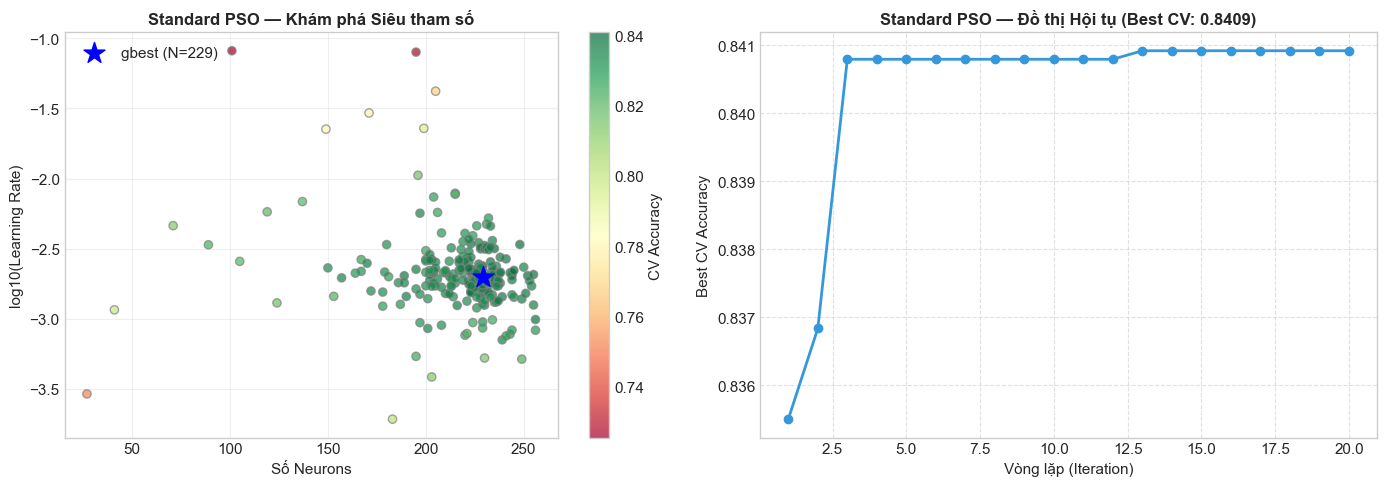

In [26]:
# Trực quan hóa Standard PSO: Không gian tìm kiếm & Đồ thị hội tụ (Format chuẩn OPSO)
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

def plot_scatter(ax, hist, n_best, lr_best, title, vmin=None, vmax=None):
    scores = hist['score']
    # Tự động căn chỉnh vmin để thang màu RdYlGn chuyển tiếp nhẹ nhàng từ đỏ sang vàng đến xanh lục (tránh bị xanh đậm do hạt cá biệt)
    if vmin is None:
        vmin = max(np.percentile(scores, 5), scores.max() - 0.025)
    if vmax is None:
        vmax = scores.max()
    sc = ax.scatter(hist['n_neurons'], np.log10(hist['lr']),
                    c=scores, cmap='RdYlGn', vmin=vmin, vmax=vmax,
                    alpha=0.6, s=40, edgecolors='grey', lw=0.3)
    ax.scatter(n_best, np.log10(lr_best), c='blue', s=250, marker='*', zorder=5, label=f'gbest (N={n_best})')
    plt.colorbar(sc, ax=ax, label='CV Accuracy')
    ax.set_xlabel('Số neurons')
    ax.set_ylabel('log10(lr)')
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8, loc='upper left')
    ax.grid(True, alpha=0.3)

plot_scatter(fig.add_subplot(gs[0, 0]), hist_std, n_std, lr_std, 'Standard PSO')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_std) + 1), conv_std, marker='o', markersize=4, linewidth=2, color='#3498db')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'Standard PSO — Đồ thị Hội tụ (Best CV: {cv_std:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🟢 2. PSO với Linear Decay Inertia Weight (PSO-LD)
- **Cơ chế:** Trọng số quán tính $w$ giảm tuyến tính theo số vòng lặp từ $w_{\text{start}} = 0.9 \to w_{\text{end}} = 0.4$:
$$w_t = w_{\text{start}} - \frac{w_{\text{start}} - w_{\text{end}}}{T} \times t$$
- **Mục tiêu:** Cân bằng linh hoạt giữa khả năng **khám phá toàn cục (Exploration)** ở những vòng lặp đầu và khả năng **khai thác cục bộ chính xác (Exploitation)** ở những vòng lặp cuối.
- **Siêu tham số:** $N = 12$ hạt, $T = 20$ vòng lặp, $c_1 = c_2 = 1.5$, $\text{seed} = 42$.

In [27]:
def run_pso_linear_decay(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_start=0.9,  
    w_end=0.4,    
    n1=1.5,
    n2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    w_history   = []  

    print(f'🟢 PSO + Linear Decay w | w_start={w_start} → w_end={w_end}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*65)
    t_start = time.time()

    for it in range(n_iter):
        t_it = time.time()
        w_current = w_start - (w_start - w_end) / n_iter * it
        w_history.append(w_current)

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al, 'w': w_current})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w_current * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | w={w_current:.3f} | gbest={gbest_score:.4f} | '
                f'neurons={n:3d}, lr={lr:.5f}, alpha={al:.6f} | [vòng: {time.time()-t_it:.1f}s, tổng: {time.time()-t_start:.0f}s]')

    print('─'*65)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    df_hist = pd.DataFrame(history)
    return gbest_pos, gbest_score, convergence, df_hist, w_history


# Chạy huấn luyện PSO Linear Decay
gbest_ld, cv_ld, conv_ld, hist_ld, w_hist_ld = run_pso_linear_decay(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)
n_ld, lr_ld, al_ld = decode_position(gbest_ld)
print(f'\n🏆 KẾT QUẢ TỐI ƯU PSO LINEAR DECAY:')
print(f'  Best Params : neurons={n_ld}, lr={lr_ld:.5f}, alpha={al_ld:.6f}')
print(f'  CV Accuracy : {cv_ld:.4f}')


🟢 PSO + Linear Decay w | w_start=0.9 → w_end=0.4
   12 particles × 20 iterations
─────────────────────────────────────────────────────────────────
  Iter  1/20 | w=0.900 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [vòng: 280.1s, tổng: 280s]
  Iter  2/20 | w=0.875 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [vòng: 1878.9s, tổng: 2159s]
  Iter  3/20 | w=0.850 | gbest=0.8373 | neurons=236, lr=0.00185, alpha=0.001400 | [vòng: 2663.8s, tổng: 4823s]
  Iter  4/20 | w=0.825 | gbest=0.8385 | neurons=242, lr=0.00203, alpha=0.009290 | [vòng: 2365.9s, tổng: 7189s]
  Iter  5/20 | w=0.800 | gbest=0.8385 | neurons=242, lr=0.00203, alpha=0.009290 | [vòng: 6756.6s, tổng: 13945s]
  Iter  6/20 | w=0.775 | gbest=0.8385 | neurons=242, lr=0.00203, alpha=0.009290 | [vòng: 1196.8s, tổng: 15142s]
  Iter  7/20 | w=0.750 | gbest=0.8385 | neurons=242, lr=0.00203, alpha=0.009290 | [vòng: 1110.8s, tổng: 16253s]
  Iter  8/20 | w=0.725 | gbest=0.8385 | neurons=242, lr=0.00203, alpha=0.00

In [28]:
# Lưu Checkpoint PSO Linear Decay
os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_ld,
    'cv_score':    cv_ld,
    'convergence': conv_ld,
    'history':     hist_ld,
    'w_history':   w_hist_ld
}, '../results/checkpoints/linear_decay_pso.pkl')

print('✅ Đã lưu kết quả Train Linear Decay PSO tại: ../results/checkpoints/linear_decay_pso.pkl')


✅ Đã lưu kết quả Train Linear Decay PSO tại: ../results/checkpoints/linear_decay_pso.pkl


In [14]:
# Trực quan hóa Linear Decay PSO: Không gian tìm kiếm & Đồ thị hội tụ (Format chuẩn OPSO)
fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_ld, n_ld, lr_ld, 'PSO + Linear Decay')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_ld) + 1), conv_ld, marker='o', markersize=4, linewidth=2, color='#2ecc71')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'Linear Decay — Đồ thị Hội tụ (Best CV: {cv_ld:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🟡 3. PSO với Fitness Averaging (PSO-FA)
- **Cơ chế:** Đánh giá điểm thích nghi của mỗi hạt qua $k = 3$ lần chạy độc lập với các hạt giống ngẫu nhiên khác nhau (`seed + run`) rồi tính giá trị trung bình.
- **Mục tiêu:** Giảm thiểu triệt để tính bất định và độ nhiễu (stochastic variance) sinh ra từ việc khởi tạo trọng số ngẫu nhiên ban đầu của mạng MLP.
- **Siêu tham số:** $N = 12$ hạt, $T = 20$ vòng lặp, $k_{\text{avg}} = 3$, $w = 0.9 \to 0.4$, $c_1 = c_2 = 1.5$.


In [3]:
def run_pso_fitness_avg(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    v_max_ratio=0.2,
    k_avg=3,     
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟡 PSO + Fitness Averaging (k={k_avg}) | w_start={w_start} → w_end={w_end}')
    print(f'   {n_particles} particles × {n_iter} iterations | tổng fitness calls ≈ {n_particles*n_iter*k_avg}')
    print('─'*65)
    t_start = time.time()

    for it in range(n_iter):
        t_it = time.time()
        w_current = w_start - (w_start - w_end) / n_iter * it

        for i in range(n_particles):
            score = fitness_averaged(positions[i], X_tr, y_tr, cv_obj, seed, k=k_avg)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = (
            w_current * velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | w={w_current:.3f} | gbest={gbest_score:.4f} | '
                f'neurons={n:3d}, lr={lr:.5f}, alpha={al:.6f} | [vòng: {time.time()-t_it:.1f}s, tổng: {time.time()-t_start:.0f}s]')

    print('─'*65)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


# Chạy huấn luyện PSO Fitness Averaging
gbest_fa, cv_fa, conv_fa, hist_fa = run_pso_fitness_avg(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_start=0.9, w_end=0.4,
    n1=1.5, n2=1.5,
    k_avg=3,
    seed=RANDOM_SEED
)
n_fa, lr_fa, al_fa = decode_position(gbest_fa)
print(f'\n🏆 KẾT QUẢ TỐI ƯU PSO FITNESS AVERAGING:')
print(f'  Best Params : neurons={n_fa}, lr={lr_fa:.5f}, alpha={al_fa:.6f}')
print(f'  CV Accuracy : {cv_fa:.4f}')


🟡 PSO + Fitness Averaging (k=3) | w_start=0.9 → w_end=0.4
   12 particles × 20 iterations | tổng fitness calls ≈ 720
─────────────────────────────────────────────────────────────────
  Iter  1/20 | w=0.900 | gbest=0.7964 | neurons=202, lr=0.00207, alpha=0.027189 | [vòng: 403.9s, tổng: 404s]
  Iter  2/20 | w=0.875 | gbest=0.7964 | neurons=202, lr=0.00207, alpha=0.027189 | [vòng: 356.3s, tổng: 760s]
  Iter  3/20 | w=0.850 | gbest=0.7989 | neurons=214, lr=0.00458, alpha=0.031414 | [vòng: 523.6s, tổng: 1284s]
  Iter  4/20 | w=0.825 | gbest=0.8019 | neurons=217, lr=0.00251, alpha=0.050501 | [vòng: 643.0s, tổng: 1927s]
  Iter  5/20 | w=0.800 | gbest=0.8019 | neurons=217, lr=0.00251, alpha=0.050501 | [vòng: 705.5s, tổng: 2632s]
  Iter  6/20 | w=0.775 | gbest=0.8019 | neurons=217, lr=0.00251, alpha=0.050501 | [vòng: 675.2s, tổng: 3307s]
  Iter  7/20 | w=0.750 | gbest=0.8019 | neurons=217, lr=0.00251, alpha=0.050501 | [vòng: 850.0s, tổng: 4157s]
  Iter  8/20 | w=0.725 | gbest=0.8019 | neurons=2

In [4]:
# Lưu Checkpoint PSO Fitness Averaging
os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_fa,
    'cv_score':    cv_fa,
    'convergence': conv_fa,
    'history':     hist_fa
}, '../results/checkpoints/fitness_avg_pso.pkl')

print('✅ Đã lưu kết quả Train Fitness Averaging PSO tại: ../results/checkpoints/fitness_avg_pso.pkl')


✅ Đã lưu kết quả Train Fitness Averaging PSO tại: ../results/checkpoints/fitness_avg_pso.pkl


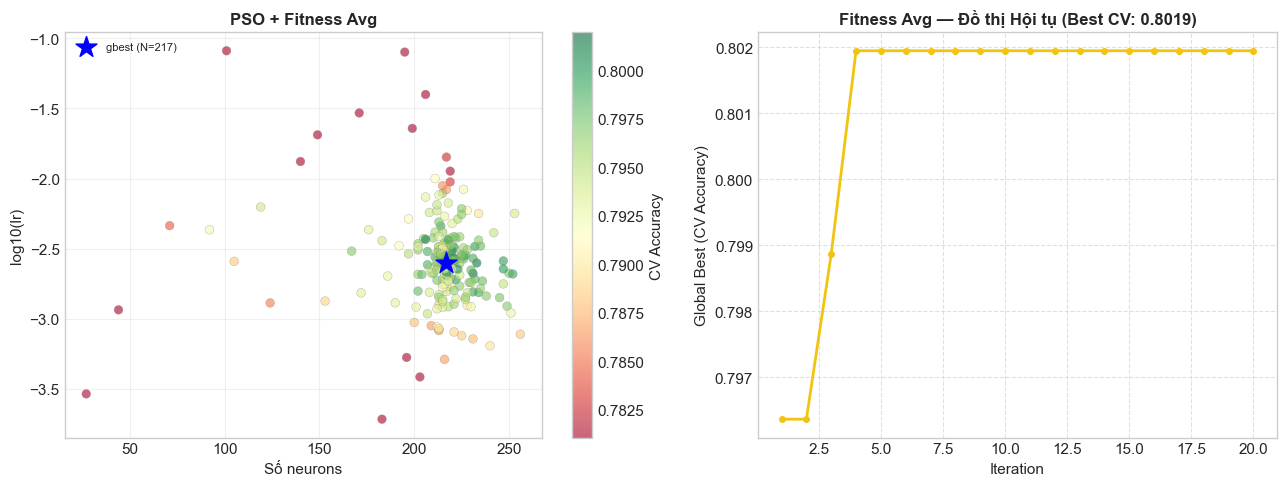

In [5]:
# Trực quan hóa PSO Fitness Averaging theo đúng format GridSpec của OPSO
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_fa, n_fa, lr_fa, 'PSO + Fitness Avg')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_fa) + 1), conv_fa, marker='o', markersize=4, linewidth=2, color='#f1c40f')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'Fitness Avg — Đồ thị Hội tụ (Best CV: {cv_fa:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🟠 4. Constriction-type PSO (CPSO)
- **Cơ chế:** Áp dụng hệ số co hẹp Clerc & Kennedy (2002) với $\phi = \eta_1 + \eta_2 = 4.1 > 4$:
$$K = \frac{2}{|2 - \phi - \sqrt{\phi^2 - 4\phi}|} \approx 0.7298$$
Phương trình vận tốc được nhân toàn bộ với hệ số $K$:
$$v_{t+1} = K \times \Big[ v_t + c_1 r_1 (p_{\text{best}} - x_t) + c_2 r_2 (g_{\text{best}} - x_t) \Big]$$
- **Mục tiêu:** Đảm bảo về mặt toán học sự hội tụ ổn định của hạt, không cần phải kẹp trần vận tốc $v_{\max}$ thủ công.
- **Siêu tham số:** $N = 12$ hạt, $T = 20$ vòng lặp, $\eta_1 = 2.05, \eta_2 = 2.05 \to \phi = 4.1, K \approx 0.7298$, $\text{seed} = 42$.


In [6]:
def compute_constriction_factor(n1, n2):
    """
    Tính Constriction Factor K — Equation (5) từ Clerc & Kennedy (2002).
    Yêu cầu: phi = n1 + n2 > 4
    """
    phi = n1 + n2
    if phi <= 4:
        raise ValueError(f'φ = n1 + n2 = {phi} phải > 4 để K có nghĩa')
    K = 2.0 / abs(2 - phi - np.sqrt(phi**2 - 4*phi))
    return K


def run_cpso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    n1=2.05,     
    n2=2.05,     
    seed=42
):
    K      = compute_constriction_factor(n1, n2)
    phi    = n1 + n2
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟠 CPSO | n1={n1}, n2={n2} | φ={phi:.2f} | K={K:.4f}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*65)
    t_start = time.time()

    for it in range(n_iter):
        t_it = time.time()
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        velocities = K * (
            velocities
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        positions = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        n, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | K={K:.4f} | gbest={gbest_score:.4f} | '
                f'neurons={n:3d}, lr={lr:.5f}, alpha={al:.6f} | [vòng: {time.time()-t_it:.1f}s, tổng: {time.time()-t_start:.0f}s]')

    print('─'*65)
    print(f'✅ Hoàn thành! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), K


# Chạy huấn luyện Constriction-type PSO
gbest_cp, cv_cp, conv_cp, hist_cp, K_val = run_cpso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    n1=2.05, n2=2.05,
    seed=RANDOM_SEED
)
n_cp, lr_cp, al_cp = decode_position(gbest_cp)
print(f'\n🏆 KẾT QUẢ TỐI ƯU CONSTRICTION PSO (CPSO):')
print(f'  Best Params : neurons={n_cp}, lr={lr_cp:.5f}, alpha={al_cp:.6f}')
print(f'  CV Accuracy : {cv_cp:.4f}')


🟠 CPSO | n1=2.05, n2=2.05 | φ=4.10 | K=0.7298
   12 particles × 20 iterations
─────────────────────────────────────────────────────────────────
  Iter  1/20 | K=0.7298 | gbest=0.7977 | neurons=215, lr=0.00785, alpha=0.010773 | [vòng: 116.8s, tổng: 117s]
  Iter  2/20 | K=0.7298 | gbest=0.8006 | neurons=219, lr=0.00179, alpha=0.008618 | [vòng: 144.1s, tổng: 261s]
  Iter  3/20 | K=0.7298 | gbest=0.8006 | neurons=219, lr=0.00179, alpha=0.008618 | [vòng: 196.0s, tổng: 457s]
  Iter  4/20 | K=0.7298 | gbest=0.8006 | neurons=219, lr=0.00179, alpha=0.008618 | [vòng: 232.8s, tổng: 690s]
  Iter  5/20 | K=0.7298 | gbest=0.8006 | neurons=219, lr=0.00179, alpha=0.008618 | [vòng: 187.5s, tổng: 877s]
  Iter  6/20 | K=0.7298 | gbest=0.8006 | neurons=219, lr=0.00179, alpha=0.008618 | [vòng: 165.7s, tổng: 1043s]
  Iter  7/20 | K=0.7298 | gbest=0.8028 | neurons=247, lr=0.00214, alpha=0.012559 | [vòng: 186.1s, tổng: 1229s]
  Iter  8/20 | K=0.7298 | gbest=0.8028 | neurons=247, lr=0.00214, alpha=0.012559 | [

In [7]:
# Lưu Checkpoint CPSO
os.makedirs('../results/checkpoints', exist_ok=True)

joblib.dump({
    'gbest_pos':   gbest_cp,
    'cv_score':    cv_cp,
    'convergence': conv_cp,
    'history':     hist_cp,
    'K_val':       K_val
}, '../results/checkpoints/cpso.pkl')

print('✅ Đã lưu kết quả Train CPSO tại: ../results/checkpoints/cpso.pkl')


✅ Đã lưu kết quả Train CPSO tại: ../results/checkpoints/cpso.pkl


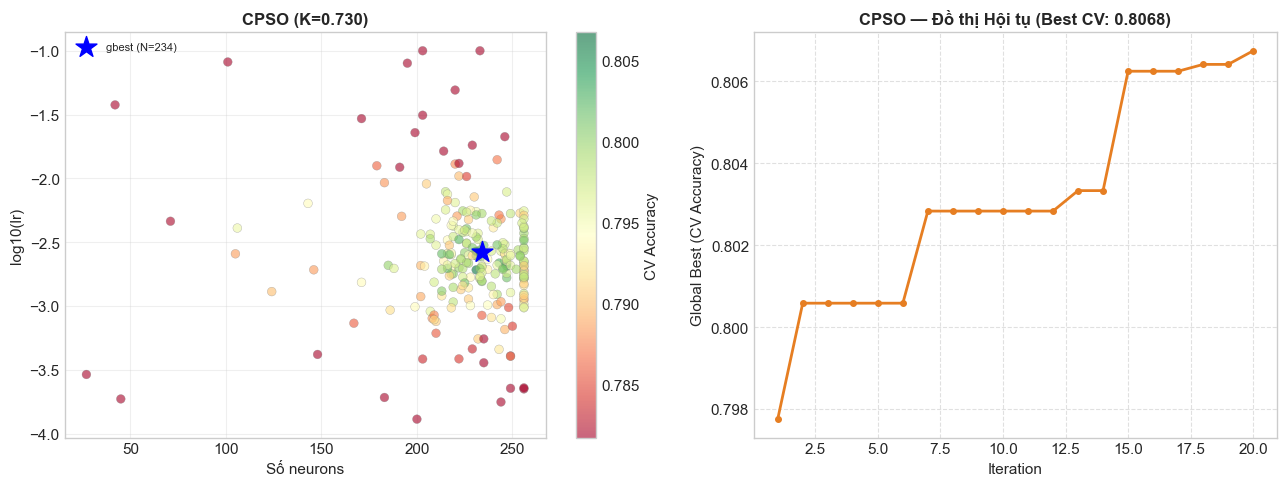

In [8]:
# Trực quan hóa CPSO theo đúng format GridSpec của OPSO
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_cp, n_cp, lr_cp, f'CPSO (K={K_val:.3f})')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_cp) + 1), conv_cp, marker='o', markersize=4, linewidth=2, color='#e67e22')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'CPSO — Đồ thị Hội tụ (Best CV: {cv_cp:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🟣 5. Fractional-Order PSO (FO-PSO)
- **Cơ chế:** Áp dụng định nghĩa vi tích phân bậc phân số Grünwald-Letnikov với chuỗi nhớ $r = 4$ thế hệ vận tốc trong quá khứ ($v_t, v_{t-1}, v_{t-2}, v_{t-3}$) và hệ số phân số $lpha = 0.6$.
- **Mục tiêu:** Giữ lại động lượng lịch sử bay để bầy hạt không bị sụp đổ vận tốc, duy trì khả năng thoát khỏi các cực tiểu địa phương.
- **Siêu tham số:** $N = 12$ hạt, $T = 20$ vòng lặp, $lpha = 0.6$, $r = 4$, $c_1 = c_2 = 1.5$.

In [13]:
def run_fopso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    alpha=0.6,    # Hệ số đạo hàm bậc phân số
    r=4,          # Số lượng v_t trong quá khứ được giữ lại
    n1=1.5, n2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    # Khởi tạo bộ nhớ cho các vận tốc trong quá khứ: v_{t}, v_{t-1}, v_{t-2}, v_{t-3}
    v_memory = np.zeros((r, n_particles, DIM))
    v_memory[0] = velocities

    # Tính các hệ số trọng lượng phân số (Fractional Coefficients)
    c_w = np.zeros(r)
    c_w[0] = alpha
    for k in range(1, r):
        c_w[k] = c_w[k-1] * (k - alpha) / (k + 1)

    print(f'🟣 FO-PSO | alpha={alpha} | r={r} | c_w={np.round(c_w, 4)}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        
        # Tính thành phần quán tính dựa trên đạo hàm bậc phân số
        inertial_velocity = np.zeros((n_particles, DIM))
        for k in range(r):
            inertial_velocity += c_w[k] * v_memory[k]
        
        velocities = (
            inertial_velocity
            + n1 * r1 * (pbest_pos - positions)
            + n2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        
        # Cập nhật bộ nhớ vận tốc 
        for k in range(r - 1, 0, -1):
            v_memory[k] = v_memory[k-1]
        v_memory[0] = velocities

        positions  = np.clip(positions + velocities, LOW, HIGH)
        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành FO-PSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

gbest_fo, cv_fo, conv_fo, hist_fo = run_fopso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    alpha=0.6, r=4,
    n1=1.5, n2=1.5,
    seed=RANDOM_SEED
)

n_fo, lr_fo, al_fo = decode_position(gbest_fo)
print(f'\n⭐ Nghiệm tối ưu FO-PSO: Neurons={n_fo}, lr={lr_fo:.5f}, alpha={al_fo:.6f} | Best CV={cv_fo:.4f}')


🟣 FO-PSO | alpha=0.6 | r=4 | c_w=[0.6    0.12   0.056  0.0336]
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [272s]
  Iter  2/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [566s]
  Iter  3/20 | gbest=0.8355 | neurons=210, lr=0.00199, alpha=0.020179 | [910s]
  Iter  4/20 | gbest=0.8355 | neurons=210, lr=0.00199, alpha=0.020179 | [1355s]
  Iter  5/20 | gbest=0.8362 | neurons=210, lr=0.00232, alpha=0.021332 | [1815s]
  Iter  6/20 | gbest=0.8382 | neurons=233, lr=0.00162, alpha=0.027931 | [2259s]
  Iter  7/20 | gbest=0.8382 | neurons=233, lr=0.00162, alpha=0.027931 | [2767s]
  Iter  8/20 | gbest=0.8389 | neurons=243, lr=0.00151, alpha=0.005616 | [3294s]
  Iter  9/20 | gbest=0.8390 | neurons=219, lr=0.00159, alpha=0.006729 | [3799s]
  Iter 10/20 | gbest=0.8392 | neurons=206, lr=0.00267, alpha=0.010048 | [4299s]
  Iter 11/20 | gbest=0.8392 | neurons=206, lr=0

In [14]:
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':   gbest_fo,
    'cv_score':    cv_fo,
    'convergence': conv_fo,
    'history':     hist_fo
}, '../results/checkpoints/fopso.pkl')
print('✅ Đã lưu kết quả FO-PSO tại: ../results/checkpoints/fopso.pkl')


✅ Đã lưu kết quả FO-PSO tại: ../results/checkpoints/fopso.pkl


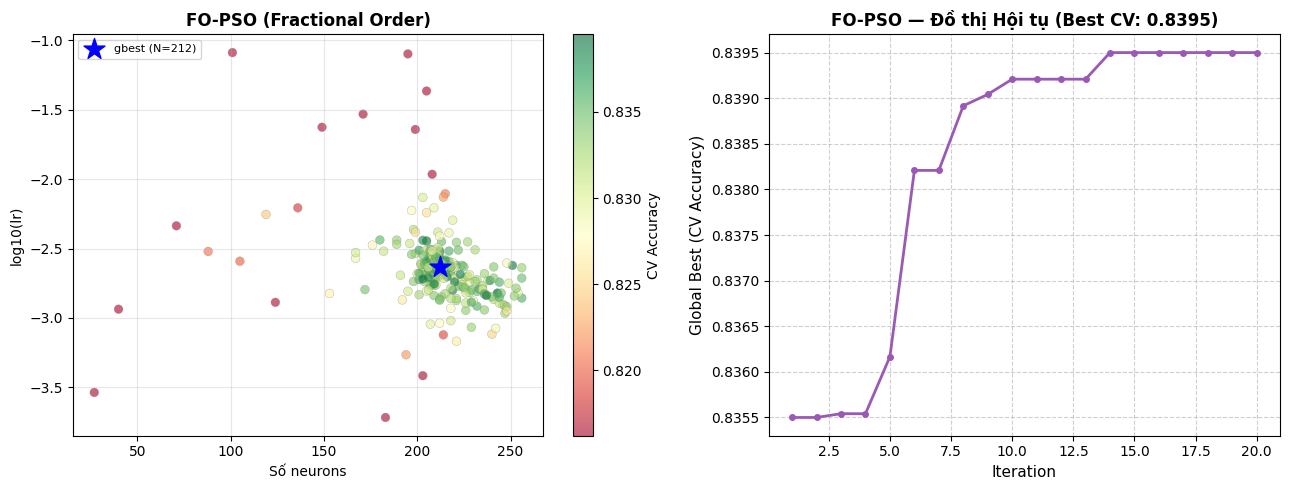

In [14]:
# Trực quan hóa FO-PSO theo đúng format GridSpec của OPSO
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_fo, n_fo, lr_fo, 'FO-PSO (Fractional Order)')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_fo) + 1), conv_fo, marker='o', markersize=4, linewidth=2, color='#9b59b6')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'FO-PSO — Đồ thị Hội tụ (Best CV: {cv_fo:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🟣 6. Angle-based Velocity PSO (A-PSO)
- **Cơ chế:** Điều chỉnh trọng số quán tính $w$ thích nghi theo từng bước lặp dựa trên góc hình học $\theta$ giữa vận tốc hiện tại $v_t$ và hướng dịch chuyển vị trí $(x_t - x_{t-1})$:
$$\cos \theta = \frac{v_t \cdot (x_t - x_{t-1})}{\|v_t\| \|x_t - x_{t-1}\|}$$
Khi $\cos \theta > 0$ (cùng hướng), tăng quán tính để bứt phá; khi $\cos \theta < 0$ (đổi hướng), giảm quán tính để hội tụ mịn quanh điểm tối ưu.
- **Mục tiêu:** Cân bằng động giữa khám phá (exploration) và khai thác (exploitation) theo trạng thái thực tế của từng hạt.
- **Siêu tham số:** $N = 12$ hạt, $T = 20$ vòng lặp, $w_{\max} = 0.9, w_{\min} = 0.2, c_1 = c_2 = 1.5$.

In [4]:
def run_apso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w_max=0.9, w_min=0.2,
    c1=1.5, c2=1.5,
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 A-PSO | Điều hướng theo góc | w: {w_max} -> {w_min} (dựa theo cos theta)')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # Tính góc giữa véc-tơ vận tốc và véc-tơ hướng về gbest
        direction_to_gbest = gbest_pos - positions
        dot_product = np.sum(velocities * direction_to_gbest, axis=1)
        norm_v = np.linalg.norm(velocities, axis=1) + 1e-8
        norm_d = np.linalg.norm(direction_to_gbest, axis=1) + 1e-8
        cos_theta = dot_product / (norm_v * norm_d)

        # Ánh xạ cos_theta từ [-1, 1] sang w từ [w_min, w_max]
        w_dynamic = w_min + (w_max - w_min) * ((cos_theta + 1.0) / 2.0)
        w_matrix = np.tile(w_dynamic, (DIM, 1)).T

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))

        velocities = (
            w_matrix * velocities
            + c1 * r1 * (pbest_pos - positions)
            + c2 * r2 * (gbest_pos - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)

        n_neur, lr, al = decode_position(gbest_pos)
        avg_w = np.mean(w_dynamic)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | avg_w={avg_w:.3f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành A-PSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy huấn luyện A-PSO
gbest_apso, cv_apso, conv_apso, hist_apso = run_apso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    w_max=0.9, w_min=0.2,
    c1=1.5, c2=1.5,
    seed=RANDOM_SEED
)

n_apso, lr_apso, al_apso = decode_position(gbest_apso)
print(f'\n⭐ Nghiệm tối ưu A-PSO: Neurons={n_apso}, lr={lr_apso:.5f}, alpha={al_apso:.6f} | Best CV={cv_apso:.4f}')


🟣 A-PSO | Điều hướng theo góc | w: 0.9 -> 0.2 (dựa theo cos theta)
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | avg_w=0.640 | [636s]
  Iter  2/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | avg_w=0.625 | [1403s]
  Iter  3/20 | gbest=0.8372 | neurons=210, lr=0.00210, alpha=0.019325 | avg_w=0.595 | [2210s]
  Iter  4/20 | gbest=0.8372 | neurons=210, lr=0.00210, alpha=0.019325 | avg_w=0.521 | [3143s]
  Iter  5/20 | gbest=0.8372 | neurons=210, lr=0.00210, alpha=0.019325 | avg_w=0.464 | [4043s]
  Iter  6/20 | gbest=0.8372 | neurons=210, lr=0.00210, alpha=0.019325 | avg_w=0.436 | [4528s]
  Iter  7/20 | gbest=0.8381 | neurons=211, lr=0.00254, alpha=0.022305 | avg_w=0.460 | [6052s]
  Iter  8/20 | gbest=0.8381 | neurons=211, lr=0.00254, alpha=0.022305 | avg_w=0.500 | [7402s]
  Iter  9/20 | gbest=0.8381 | neurons=211, lr=0.00254, alpha=0.022305 | avg_w=0.318 | [82

In [5]:
# Lưu Checkpoint A-PSO
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':   gbest_apso,
    'cv_score':    cv_apso,
    'convergence': conv_apso,
    'history':     hist_apso
}, '../results/checkpoints/apso.pkl')
print('✅ Đã lưu kết quả A-PSO tại: ../results/checkpoints/apso.pkl')


✅ Đã lưu kết quả A-PSO tại: ../results/checkpoints/apso.pkl


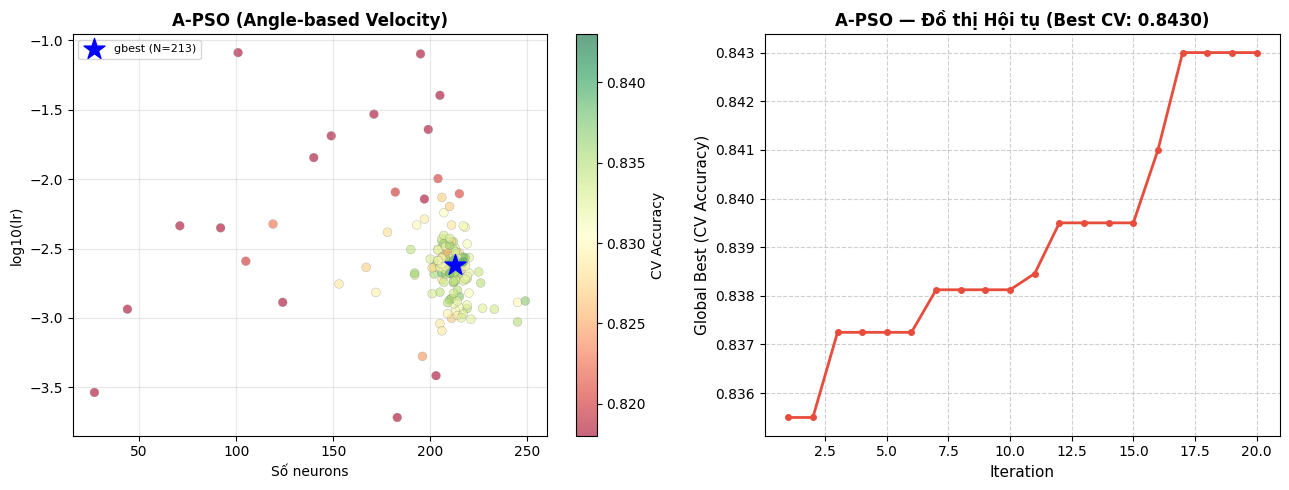

In [16]:
# Trực quan hóa A-PSO
fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_apso, n_apso, lr_apso, 'A-PSO (Angle-based Velocity)')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_apso) + 1), conv_apso, marker='o', markersize=4, linewidth=2, color='#1abc9c')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'A-PSO — Đồ thị Hội tụ (Best CV: {cv_apso:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🟣 7. Non-linear Attraction PSO (NL-PSO)
- **Cơ chế:** Thay thế khoảng cách tuyến tính $(p_{\text{best}} - x)$ và $(g_{\text{best}} - x)$ bằng hàm phi tuyến với số mũ $\gamma = 2.0$:
$$v_{t+1} = w v_t + c_1 r_1 \mathrm{sgn}(p_{\text{best}} - x_t) |p_{\text{best}} - x_t|^\gamma + c_2 r_2 \mathrm{sgn}(g_{\text{best}} - x_t) |g_{\text{best}} - x_t|^\gamma$$
- **Mục tiêu:** Tạo lực hút phi tuyến mạnh mẽ khi hạt ở xa cực trị để nhanh chóng kéo bầy về vùng tiềm năng, và lực hút cực nhỏ khi ở gần để tinh chỉnh nghiệm mà không gây dao động quá mức.
- **Siêu tham số:** $N = 12$ hạt, $T = 20$ vòng lặp, $w = 0.729, c_1 = c_2 = 1.49445, \gamma = 2.0$.

In [ ]:
def run_nl_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.729, c1=1.49445, c2=1.49445,
    gamma=2.0, # Hệ số phi tuyến
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)
    space_range = (HIGH - LOW) + 1e-8 # Tránh chia cho 0

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 NL-PSO | Lực hút phi tuyến | w={w}, c1={c1}, c2={c2}, gamma={gamma}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        
        # --- NON-LINEAR ATTRACTION LOGIC ---
        # 1. Khoảng cách vật lý
        dist_p = pbest_pos - positions
        dist_g = gbest_pos - positions
        
        # 2. Chuẩn hóa khoảng cách về [0, 1] so với không gian
        norm_dist_p = np.abs(dist_p) / space_range
        norm_dist_g = np.abs(dist_g) / space_range
        
        # 3. Tính lực phi tuyến qua hàm (1 - e^(-gamma * x)) và khôi phục tỷ lệ
        nl_attraction_p = np.sign(dist_p) * (1 - np.exp(-gamma * norm_dist_p)) * space_range
        nl_attraction_g = np.sign(dist_g) * (1 - np.exp(-gamma * norm_dist_g)) * space_range

        velocities = (
            w * velocities
            + c1 * r1 * nl_attraction_p
            + c2 * r2 * nl_attraction_g
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành NL-PSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy huấn luyện NL-PSO
gbest_nl, cv_nl, conv_nl, hist_nl = run_nl_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    gamma=2.0,
    seed=RANDOM_SEED
)

n_nl, lr_nl, al_nl = decode_position(gbest_nl)
print(f'\n⭐ Nghiệm tối ưu NL-PSO: Neurons={n_nl}, lr={lr_nl:.5f}, alpha={al_nl:.6f} | Best CV={cv_nl:.4f}')


🟣 NL-PSO | Lực hút phi tuyến | w=0.729, c1=1.49445, c2=1.49445, gamma=2.0
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [724s]
  Iter  2/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [1330s]
  Iter  3/20 | gbest=0.8383 | neurons=201, lr=0.00205, alpha=0.002280 | [2052s]
  Iter  4/20 | gbest=0.8383 | neurons=201, lr=0.00205, alpha=0.002280 | [2821s]
  Iter  5/20 | gbest=0.8383 | neurons=201, lr=0.00205, alpha=0.002280 | [3587s]
  Iter  6/20 | gbest=0.8383 | neurons=201, lr=0.00205, alpha=0.002280 | [4420s]
  Iter  7/20 | gbest=0.8383 | neurons=201, lr=0.00205, alpha=0.002280 | [5156s]
  Iter  8/20 | gbest=0.8390 | neurons=233, lr=0.00164, alpha=0.006173 | [5977s]
  Iter  9/20 | gbest=0.8390 | neurons=233, lr=0.00164, alpha=0.006173 | [7004s]
  Iter 10/20 | gbest=0.8390 | neurons=233, lr=0.00164, alpha=0.006173 | [8204s]
  Iter 11/20 | gbest=0.8390 | neur

In [ ]:
# Lưu Checkpoint NL-PSO
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':   gbest_nl,
    'cv_score':    cv_nl,
    'convergence': conv_nl,
    'history':     hist_nl
}, '../results/checkpoints/nl_pso.pkl')
print('✅ Đã lưu kết quả NL-PSO tại: ../results/checkpoints/nl_pso.pkl')


✅ Đã lưu kết quả NL-PSO tại: ../results/checkpoints/nl_pso.pkl


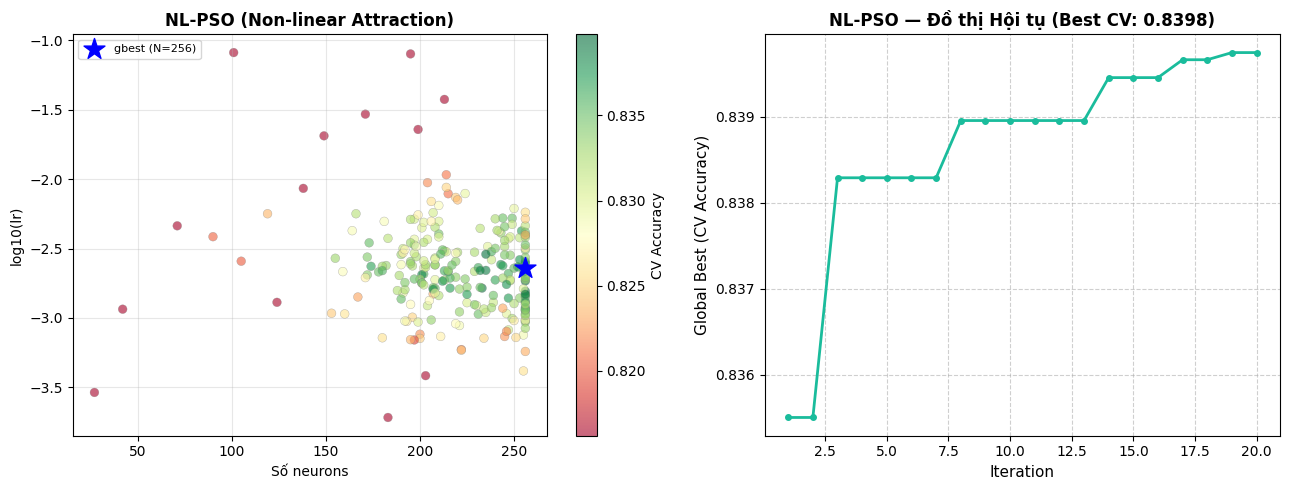

In [17]:
# Trực quan hóa NL-PSO
fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_nl, n_nl, lr_nl, 'NL-PSO (Non-linear Attraction)')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_nl) + 1), conv_nl, marker='o', markersize=4, linewidth=2, color='#e74c3c')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'NL-PSO — Đồ thị Hội tụ (Best CV: {cv_nl:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🟣 8. Mean-based / Top-K Attraction PSO (MB-PSO)
- **Cơ chế:** Bổ sung lực hút xã hội thứ 3 hướng về trọng tâm (centroid) $\bar{x}_{\text{top-}k}$ của Top-$k$ ($k=4$) hạt có điểm thích nghi cao nhất:
$$v_{t+1} = w v_t + c_1 r_1 (p_{\text{best}} - x_t) + c_2 r_2 (g_{\text{best}} - x_t) + c_3 r_3 (\bar{x}_{\text{top-}k} - x_t)$$
với $\bar{x}_{\text{top-}k} = \frac{1}{k} \sum_{j=1}^k p_{\text{best}, j}$.
- **Mục tiêu:** Giảm thiểu sự phụ thuộc độc tôn vào hạt $g_{\text{best}}$ đơn lẻ, tận dụng trí tuệ tập thể từ nhóm dẫn đầu để định hướng bầy hiệu quả hơn.
- **Siêu tham số:** $N = 12$ hạt, $T = 20$ vòng lặp, $w = 0.729, c_1 = c_2 = c_3 = 1.0, \text{top\_k} = 4$.

In [4]:
def run_mb_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    w=0.729, c1=1.0, c2=1.0, c3=1.0, 
    top_k=4, 
    v_max_ratio=0.2,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    v_max  = v_max_ratio * (HIGH - LOW)

    positions  = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    velocities = rng.uniform(-(HIGH-LOW)*0.1, (HIGH-LOW)*0.1, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟣 MB-PSO | Mean-based (Top-{top_k}) Attraction | w={w}, c1=c2=c3={c1}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─'*60)
    t_start = time.time()

    for it in range(n_iter):
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({'iter': it, 'particle': i, 'score': score,
                            'n_neurons': n_neur, 'lr': lr, 'alpha': al})
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # 1. Tìm Top-K hạt có pbest_score cao nhất
        top_indices = np.argsort(pbest_score)[-top_k:]
        
        # 2. Tính tọa độ trọng tâm mbest
        mbest = np.mean(pbest_pos[top_indices], axis=0)

        # 3. Ba ma trận ngẫu nhiên cho 3 lực kéo
        r1 = rng.random(size=(n_particles, DIM))
        r2 = rng.random(size=(n_particles, DIM))
        r3 = rng.random(size=(n_particles, DIM))
        
        # Cập nhật vận tốc với 3 lực kéo (pbest, gbest, mbest)
        velocities = (
            w * velocities
            + c1 * r1 * (pbest_pos - positions)
            + c2 * r2 * (gbest_pos - positions)
            + c3 * r3 * (mbest - positions)
        )
        velocities = np.clip(velocities, -v_max, v_max)
        positions  = np.clip(positions + velocities, LOW, HIGH)

        convergence.append(gbest_score)
        
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | gbest={gbest_score:.4f} | '
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─'*60)
    print(f'✅ Hoàn thành MB-PSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy huấn luyện MB-PSO
gbest_mb, cv_mb, conv_mb, hist_mb = run_mb_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    top_k=4,
    seed=RANDOM_SEED
)

n_mb, lr_mb, al_mb = decode_position(gbest_mb)
print(f'\n⭐ Nghiệm tối ưu MB-PSO: Neurons={n_mb}, lr={lr_mb:.5f}, alpha={al_mb:.6f} | Best CV={cv_mb:.4f}')


🟣 MB-PSO | Mean-based (Top-4) Attraction | w=0.729, c1=c2=c3=1.0
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [678s]
  Iter  2/20 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [1279s]
  Iter  3/20 | gbest=0.8372 | neurons=220, lr=0.00180, alpha=0.003788 | [1970s]
  Iter  4/20 | gbest=0.8372 | neurons=220, lr=0.00180, alpha=0.003788 | [2973s]
  Iter  5/20 | gbest=0.8372 | neurons=220, lr=0.00180, alpha=0.003788 | [4016s]
  Iter  6/20 | gbest=0.8372 | neurons=220, lr=0.00180, alpha=0.003788 | [4853s]
  Iter  7/20 | gbest=0.8378 | neurons=203, lr=0.00229, alpha=0.008396 | [5595s]
  Iter  8/20 | gbest=0.8390 | neurons=193, lr=0.00420, alpha=0.007457 | [6372s]
  Iter  9/20 | gbest=0.8390 | neurons=193, lr=0.00420, alpha=0.007457 | [7149s]
  Iter 10/20 | gbest=0.8390 | neurons=193, lr=0.00420, alpha=0.007457 | [7732s]
  Iter 11/20 | gbest=0.8390 | neurons=193, 

In [5]:
# Lưu Checkpoint MB-PSO
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':   gbest_mb,
    'cv_score':    cv_mb,
    'convergence': conv_mb,
    'history':     hist_mb
}, '../results/checkpoints/mbpso.pkl')
print('✅ Đã lưu kết quả MB-PSO tại: ../results/checkpoints/mbpso.pkl')


✅ Đã lưu kết quả MB-PSO tại: ../results/checkpoints/mbpso.pkl


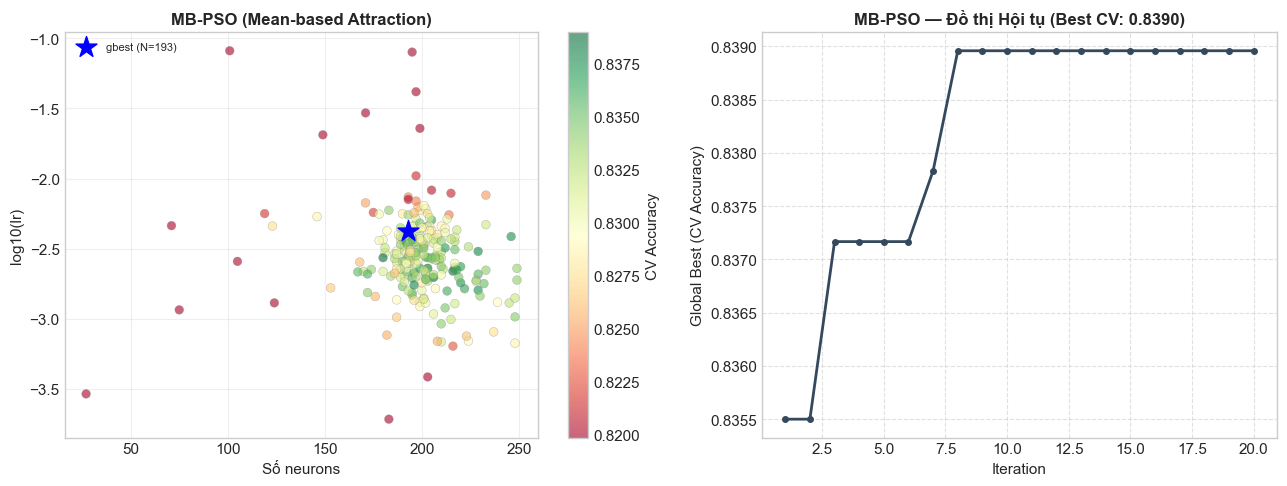

In [7]:
# Trực quan hóa MB-PSO
fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_mb, n_mb, lr_mb, 'MB-PSO (Mean-based Attraction)')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_mb) + 1), conv_mb, marker='o', markersize=4, linewidth=2, color='#34495e')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'MB-PSO — Đồ thị Hội tụ (Best CV: {cv_mb:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## ⚛️ 9. Thuật toán Quantum-inspired PSO (QPSO / Q-SPSO)
- **Cơ chế:** Loại bỏ hoàn toàn vector vận tốc (velocity-free). Vị trí hạt được cập nhật dựa trên hàm sóng xác suất lượng tử, điểm thu hút cá nhân - bầy đàn $p$ và khoảng cách tới trọng tâm trung bình $mbest$.
- **Phương trình lượng tử:**
  $$mbest = \frac{1}{N} \sum_{i=1}^N pbest_i$$
  $$p_i = \phi \cdot pbest_i + (1 - \phi) \cdot gbest, \quad \phi \sim U(0, 1)$$
  $$x_i^{(t+1)} = p_i \pm \beta \cdot |mbest - x_i^{(t)}| \cdot \ln(1/u), \quad u \sim U(0, 1)$$
- **Hệ số $\beta$:** Suy giảm tuyến tính $\beta: 1.0 \to 0.5$ qua 20 vòng lặp.

In [25]:
def run_qpso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []

    print(f'⚛️ QPSO (Quantum-inspired PSO) | beta: {beta_start} -> {beta_end}', flush=True)
    print(f'   {n_particles} particles × {n_iter} iterations', flush=True)
    print(f'   Velocity-free: cập nhật vị trí bằng hàm mật độ xác suất lượng tử', flush=True)
    print('─' * 60, flush=True)
    t_start = time.time()

    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        beta_history.append(beta)

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # Quantum Position Update
        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos

            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)

            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | ' 
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]', flush=True)

    print('─' * 60, flush=True)
    print(f'✅ Hoàn thành QPSO! Thời gian: {time.time()-t_start:.1f}s', flush=True)
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history

# Kiểm tra checkpoint đã lưu trước khi chạy huấn luyện
ckpt_qpso_path = '../results/checkpoints/qpso.pkl'
if not os.path.exists(ckpt_qpso_path):
    ckpt_qpso_path = 'results/checkpoints/qpso.pkl'

if os.path.exists(ckpt_qpso_path):
    print(f'📦 Đã tìm thấy checkpoint QPSO có sẵn tại: {ckpt_qpso_path}', flush=True)
    _ckpt_q = joblib.load(ckpt_qpso_path)
    gbest_qpso = _ckpt_q['gbest_pos']
    cv_qpso = _ckpt_q['cv_score']
    conv_qpso = _ckpt_q['convergence']
    hist_qpso = _ckpt_q['history']
    beta_hist_qpso = _ckpt_q.get('beta_history', [])
    print('✅ Nạp thành công kết quả tối ưu QPSO từ checkpoint!', flush=True)
else:
    # Chạy huấn luyện QPSO
    gbest_qpso, cv_qpso, conv_qpso, hist_qpso, beta_hist_qpso = run_qpso(
        X_train_sc, y_train,
        n_particles=12, n_iter=20,
        beta_start=1.0, beta_end=0.5,
        seed=RANDOM_SEED
    )

n_qpso, lr_qpso, al_qpso = decode_position(gbest_qpso)
print(f'\n⭐ Nghiệm tối ưu QPSO: Neurons={n_qpso}, lr={lr_qpso:.5f}, alpha={al_qpso:.6f} | Best CV={cv_qpso:.4f}', flush=True)

📦 Đã tìm thấy checkpoint QPSO có sẵn tại: ../results/checkpoints/qpso.pkl
✅ Nạp thành công kết quả tối ưu QPSO từ checkpoint!

⭐ Nghiệm tối ưu QPSO: Neurons=256, lr=0.00234, alpha=0.001012 | Best CV=0.8421


In [26]:
# Lưu Checkpoint QPSO
ckpt_dir = '../results/checkpoints' if os.path.exists('../results') else 'results/checkpoints'
os.makedirs(ckpt_dir, exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_qpso,
    'cv_score':     cv_qpso,
    'convergence':  conv_qpso,
    'history':      hist_qpso,
    'beta_history': beta_hist_qpso
}, os.path.join(ckpt_dir, 'qpso.pkl'))
print(f'✅ Đã lưu kết quả QPSO tại: {os.path.join(ckpt_dir, "qpso.pkl")}', flush=True)

✅ Đã lưu checkpoint QPSO thành công!
   Đường dẫn: ../results/checkpoints/qpso.pkl
   Nghiệm tốt nhất: Neurons=256, lr=0.00234, alpha=0.001012
   Độ chính xác CV: 0.8421


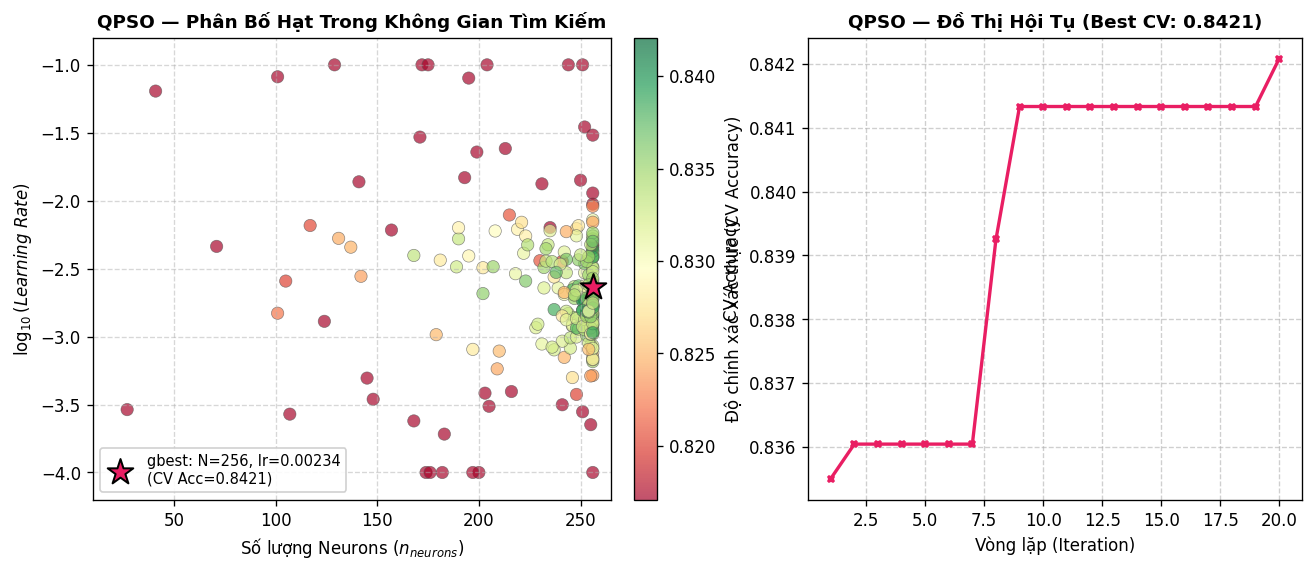

In [27]:
# Trực quan hóa QPSO
fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_qpso, n_qpso, lr_qpso, 'QPSO (Quantum-inspired PSO)')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_qpso) + 1), conv_qpso, marker='o', markersize=4, linewidth=2, color='#e91e63')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'QPSO — Đồ thị Hội tụ (Best CV: {cv_qpso:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 🟢 10. Quantum + Linear Decay PSO (Q-LDPSO)
- **Cơ chế:** Kết hợp cơ chế lượng tử QPSO với trọng số suy giảm tuyến tính $w(t): 0.9 \to 0.4$ để điều phối điểm thu hút $p$:
  $$p_i = w(t) \cdot \phi \cdot pbest_i + (1 - w(t) \cdot \phi) \cdot gbest$$
- **Mục tiêu:** Đầu chu kỳ ($w$ cao): Hạt ưu tiên tự tin vào kinh nghiệm cá nhân $pbest$ để mở rộng tìm kiếm; cuối chu kỳ ($w$ thấp): Điểm hút kéo mạnh về $gbest$ để hội tụ chính xác.

In [ ]:
def run_q_ldpso(
    X_tr, y_tr, 
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    w_start=0.9, w_end=0.4,
    seed=42
):
    rng = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🟢 Q-LDPSO (Quantum + Linear Decay)', flush=True)
    print(f'   beta: {beta_start} → {beta_end} | w: {w_start} → {w_end}', flush=True)
    print('─' * 60, flush=True)
    t_start = time.time()

    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))
        w    = w_start - (w_start - w_end) * (it / max(n_iter - 1, 1))

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = w * phi * pbest_pos[i] + (1.0 - w * phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur_best, lr_best, al_best = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | w={w:.3f} | gbest={gbest_score:.4f} | ' 
              f'neurons={n_neur_best:3d}, lr={lr_best:.5f} | [{time.time()-t_start:.0f}s]', flush=True)

    print('─' * 60, flush=True)
    print(f'✅ Hoàn thành Q-LDPSO! Thời gian: {time.time()-t_start:.1f}s', flush=True)
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


In [ ]:
# Lưu / Nạp Checkpoint Q-LDPSO
ckpt_dir = '../results/checkpoints' if os.path.exists('../results/checkpoints') else 'results/checkpoints'
os.makedirs(ckpt_dir, exist_ok=True)
ckpt_qld_path = os.path.join(ckpt_dir, 'q_ldpso.pkl')

if os.path.exists(ckpt_qld_path):
    print(f'📦 Nạp lại kết quả Q-LDPSO từ checkpoint: {ckpt_qld_path}', flush=True)
    _saved = joblib.load(ckpt_qld_path)
    gbest_qld = _saved['gbest_pos']
    cv_qld = _saved['cv_score']
    conv_qld = _saved['convergence']
    hist_qld = pd.DataFrame(_saved['history']) if isinstance(_saved['history'], list) else _saved['history']
else:
    gbest_qld, cv_qld, conv_qld, hist_qld = run_q_ldpso(
        X_train_sc, y_train,
        n_particles=12, n_iter=20,
        beta_start=1.0, beta_end=0.5,
        w_start=0.9, w_end=0.4,
        seed=RANDOM_SEED
    )
    joblib.dump({
        'gbest_pos':    gbest_qld,
        'cv_score':     cv_qld,
        'convergence':  conv_qld,
        'history':      hist_qld
    }, ckpt_qld_path)

n_qld, lr_qld, al_qld = decode_position(gbest_qld)
print(f'✅ Đã nạp checkpoint Q-LDPSO thành công!')
print(f'   Đường dẫn: {ckpt_qld_path}')
print(f'   Nghiệm tốt nhất: Neurons={n_qld}, lr={lr_qld:.5f}, alpha={al_qld:.6f}')
print(f'   Độ chính xác CV: {cv_qld:.4f}')


📦 Nạp lại kết quả Q-LDPSO từ checkpoint: ../results/checkpoints/q_ldpso.pkl
✅ Đã nạp checkpoint Q-LDPSO thành công!
   Đường dẫn: ../results/checkpoints/q_ldpso.pkl
   Nghiệm tốt nhất: Neurons=256, lr=0.00198, alpha=0.002754
   Độ chính xác CV: 0.8418


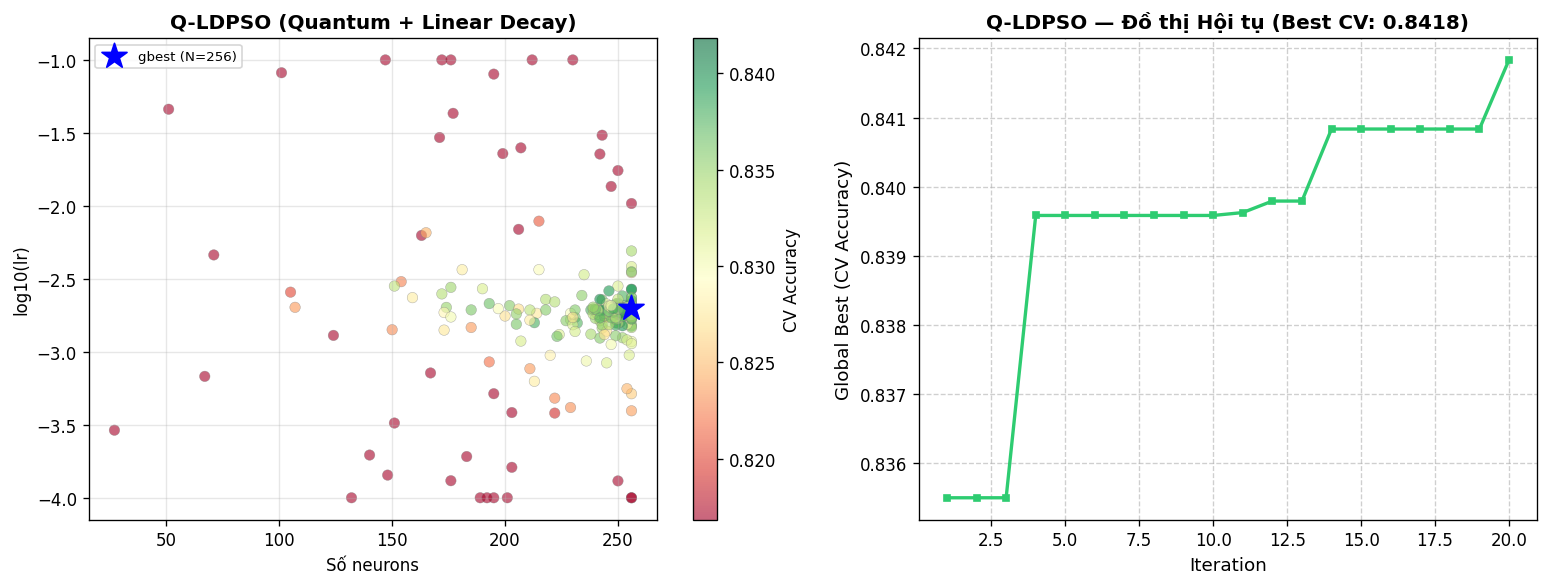

In [ ]:
# Trực quan hóa Q-LDPSO
fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_qld, n_qld, lr_qld, 'Q-LDPSO (Quantum + Linear Decay)')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_qld) + 1), conv_qld, marker='s', markersize=4, linewidth=2, color='#2ecc71')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'Q-LDPSO — Đồ thị Hội tụ (Best CV: {cv_qld:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🌀 11. Quantum + Top-K Mean-Based PSO (Q-MBPSO)
- **Cơ chế:** Thay vì tính $mbest$ trên toàn bộ bầy đàn ($N$ hạt), Q-MBPSO chỉ tính trung tâm trên Top-$K$ hạt có $pbest$ cao nhất ($K=3$):
  $$mbest_{TopK} = \frac{1}{K} \sum_{j \in TopK} pbest_j$$
  $$x_i^{(t+1)} = p_i \pm \beta \cdot |mbest_{TopK} - x_i^{(t)}| \cdot \ln(1/u)$$
- **Mục tiêu:** Loại bỏ hoàn toàn sự kéo lệch trọng tâm của các hạt có điểm thích nghi kém, định hướng bầy theo nhóm tinh anh.

In [ ]:
def run_q_mbpso(
    X_tr, y_tr, 
    n_particles=12, n_iter=20, 
    beta_start=1.0, beta_end=0.5, 
    top_k=3, 
    seed=42
):
    rng = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []

    print(f'🌀 Q-MBPSO (Quantum MB-PSO) | mbest = Top-{top_k} pbest | beta: {beta_start} → {beta_end}', flush=True)
    print('─' * 60, flush=True)
    t_start = time.time()

    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        top_k_idx = np.argsort(pbest_score)[-top_k:]
        mbest_topk = np.mean(pbest_pos[top_k_idx], axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest_topk - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur_best, lr_best, al_best = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | ' 
              f'neurons={n_neur_best:3d}, lr={lr_best:.5f} | [{time.time()-t_start:.0f}s]', flush=True)

    print('─' * 60, flush=True)
    print(f'✅ Hoàn thành Q-MBPSO! Thời gian: {time.time()-t_start:.1f}s', flush=True)
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)


In [ ]:
# Lưu / Nạp Checkpoint Q-MBPSO
ckpt_dir = '../results/checkpoints' if os.path.exists('../results/checkpoints') else 'results/checkpoints'
os.makedirs(ckpt_dir, exist_ok=True)
ckpt_qmb_path = os.path.join(ckpt_dir, 'q_mbpso.pkl')

if os.path.exists(ckpt_qmb_path):
    print(f'📦 Nạp lại kết quả Q-MBPSO từ checkpoint: {ckpt_qmb_path}', flush=True)
    _saved = joblib.load(ckpt_qmb_path)
    gbest_qmb = _saved['gbest_pos']
    cv_qmb = _saved['cv_score']
    conv_qmb = _saved['convergence']
    hist_qmb = pd.DataFrame(_saved['history']) if isinstance(_saved['history'], list) else _saved['history']
else:
    gbest_qmb, cv_qmb, conv_qmb, hist_qmb = run_q_mbpso(
        X_train_sc, y_train,
        n_particles=12, n_iter=20,
        beta_start=1.0, beta_end=0.5,
        top_k=3,
        seed=RANDOM_SEED
    )
    joblib.dump({
        'gbest_pos':    gbest_qmb,
        'cv_score':     cv_qmb,
        'convergence':  conv_qmb,
        'history':      hist_qmb
    }, ckpt_qmb_path)

n_qmb, lr_qmb, al_qmb = decode_position(gbest_qmb)
print(f'✅ Đã nạp checkpoint Q-MBPSO thành công!')
print(f'   Đường dẫn: {ckpt_qmb_path}')
print(f'   Nghiệm tốt nhất: Neurons={n_qmb}, lr={lr_qmb:.5f}, alpha={al_qmb:.6f}')
print(f'   Độ chính xác CV: {cv_qmb:.4f}')


📦 Nạp lại kết quả Q-MBPSO từ checkpoint: ../results/checkpoints/q_mbpso.pkl
✅ Đã nạp checkpoint Q-MBPSO thành công!
   Đường dẫn: ../results/checkpoints/q_mbpso.pkl
   Nghiệm tốt nhất: Neurons=238, lr=0.00219, alpha=0.000952
   Độ chính xác CV: 0.8414


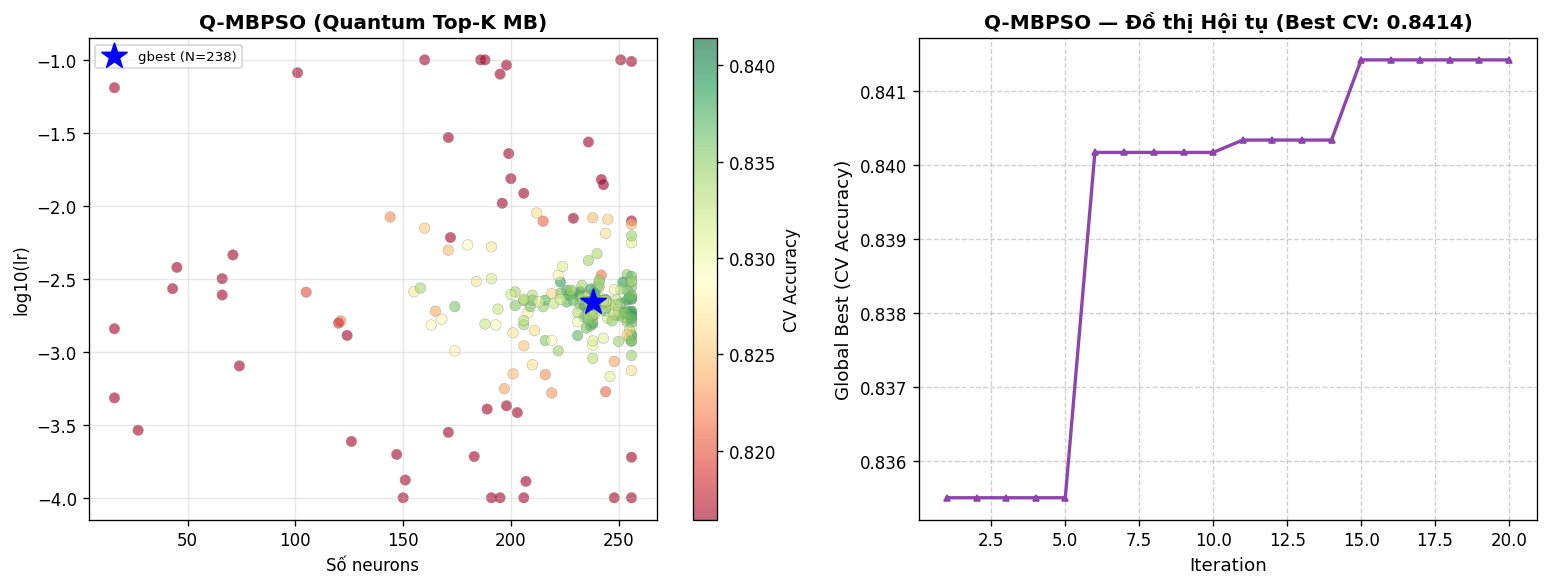

In [ ]:
# Trực quan hóa Q-MBPSO
fig = plt.figure(figsize=(13, 5))
gs = gridspec.GridSpec(1, 2, figure=fig, width_ratios=[1.15, 1])

plot_scatter(fig.add_subplot(gs[0, 0]), hist_qmb, n_qmb, lr_qmb, 'Q-MBPSO (Quantum Top-K MB)')

ax_conv = fig.add_subplot(gs[0, 1])
ax_conv.plot(range(1, len(conv_qmb) + 1), conv_qmb, marker='^', markersize=4, linewidth=2, color='#8e44ad')
ax_conv.set_xlabel('Iteration', fontsize=11)
ax_conv.set_ylabel('Global Best (CV Accuracy)', fontsize=11)
ax_conv.set_title(f'Q-MBPSO — Đồ thị Hội tụ (Best CV: {cv_qmb:.4f})', fontsize=12, fontweight='bold')
ax_conv.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


## 🚀 12. QPSO với Adaptive $\beta$ phi tuyến (Cosine Annealing Beta)
- **Cơ chế:** Thay vì giảm $\beta$ tuyến tính, áp dụng hàm Cosine Annealing để chuyển tiếp mượt mà:
  $$\beta(t) = \beta_{end} + \frac{1}{2}(\beta_{start} - \beta_{end}) \left[ 1 + \cos\left(\frac{\pi \cdot t}{T_{max}}\right) \right]$$
- **Mục tiêu:** Giữ $\beta$ lớn lâu hơn ở đầu để thăm dò rộng, sau đó suy giảm êm ái về $\beta_{end} = 0.5$ để khai thác cực trị chính xác.

In [4]:
def run_qpso_nonlinear(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []

    print(f'⚛️ QPSO (Non-linear Cosine Decay) | beta: {beta_start} -> {beta_end}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─' * 60)
    t_start = time.time()

    for it in range(n_iter):
        beta = beta_end + 0.5 * (beta_start - beta_end) * (1.0 + math.cos(math.pi * it / n_iter))
        beta_history.append(beta)

        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | ' 
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─' * 60)
    print(f'✅ Hoàn thành QPSO Non-linear! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history

# Chạy huấn luyện QPSO Nonlinear
gbest_qpso_nl, cv_qpso_nl, conv_qpso_nl, hist_qpso_nl, beta_hist_qpso_nl = run_qpso_nonlinear(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso_nl, lr_qpso_nl, al_qpso_nl = decode_position(gbest_qpso_nl)
print(f'\n⭐ Nghiệm tối ưu QPSO Nonlinear: Neurons={n_qpso_nl}, lr={lr_qpso_nl:.5f}, alpha={al_qpso_nl:.6f} | Best CV={cv_qpso_nl:.4f}')

⚛️ QPSO (Non-linear Cosine Decay) | beta: 1.0 -> 0.5
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | beta=1.000 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [567s]
  Iter  2/20 | beta=0.997 | gbest=0.8360 | neurons=256, lr=0.00524, alpha=0.001815 | [1058s]
  Iter  3/20 | beta=0.988 | gbest=0.8365 | neurons=252, lr=0.00291, alpha=0.000712 | [1466s]
  Iter  4/20 | beta=0.973 | gbest=0.8365 | neurons=252, lr=0.00291, alpha=0.000712 | [1841s]
  Iter  5/20 | beta=0.952 | gbest=0.8370 | neurons=185, lr=0.00344, alpha=0.000991 | [2123s]
  Iter  6/20 | beta=0.927 | gbest=0.8378 | neurons=185, lr=0.00338, alpha=0.000506 | [2408s]
  Iter  7/20 | beta=0.897 | gbest=0.8378 | neurons=185, lr=0.00338, alpha=0.000506 | [2735s]
  Iter  8/20 | beta=0.863 | gbest=0.8412 | neurons=256, lr=0.00187, alpha=0.003643 | [3065s]
  Iter  9/20 | beta=0.827 | gbest=0.8412 | neurons=256, lr=0.00187, alpha=0.003643 | [3598s]
  Iter 10/20 | bet

In [5]:
# Lưu Checkpoint QPSO Nonlinear
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':     gbest_qpso_nl,
    'cv_score':      cv_qpso_nl,
    'convergence':   conv_qpso_nl,
    'history':       hist_qpso_nl.to_dict('records') if hasattr(hist_qpso_nl, 'to_dict') else hist_qpso_nl,
    'beta_history':  beta_hist_qpso_nl
}, '../results/checkpoints/qpso_nonlinear.pkl')
print('✅ Đã lưu checkpoint QPSO Nonlinear tại: ../results/checkpoints/qpso_nonlinear.pkl')

✅ Đã lưu checkpoint QPSO Nonlinear tại: ../results/checkpoints/qpso_nonlinear.pkl


## 🚀 13. QPSO với Fitness-adaptive $\beta$ (Thích ứng theo tiến trình hội tụ)
- **Cơ chế:** Giám sát sự trì trệ của bầy đàn qua `stagnation_limit = 3`:
  - Nếu $gbest$ cải thiện: Giảm nhẹ $\beta \leftarrow \max(\beta_{end}, \beta \times 0.9)$ để tập trung khai thác sâu.
  - Nếu bế tắc liên tiếp $\ge 3$ vòng không tiến triển: Bơm $\beta = 1.0$ (kích hoạt đột phá lượng tử) để phá vỡ cực tiểu địa phương.

In [6]:
def run_qpso_adaptive(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    stagnation_limit=3,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    beta_history = []
    
    stagnation_counter = 0
    beta = beta_start

    print(f'⚛️ QPSO (Fitness-Adaptive Beta) | beta: {beta_start} -> {beta_end} | stagnation_limit={stagnation_limit}')
    print('─' * 60)
    t_start = time.time()

    for it in range(n_iter):
        improved = False
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta
            })

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()
                improved    = True

        beta_history.append(beta)

        # Logic thích ứng beta
        if improved:
            stagnation_counter = 0
            beta = max(beta_end, beta * 0.9)
        else:
            stagnation_counter += 1
            beta = max(beta_end, beta * 0.9)
            if stagnation_counter >= stagnation_limit:
                beta = beta_start  # Bơm lại beta để thoát cực trị
                stagnation_counter = 0

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta_history[-1]:.3f} (stagnation={stagnation_counter}) | ' 
              f'gbest={gbest_score:.4f} | neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─' * 60)
    print(f'✅ Hoàn thành QPSO Adaptive! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), beta_history

# Chạy huấn luyện QPSO Adaptive
gbest_qpso_ad, cv_qpso_ad, conv_qpso_ad, hist_qpso_ad, beta_hist_qpso_ad = run_qpso_adaptive(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    stagnation_limit=3,
    seed=RANDOM_SEED
)
n_qpso_ad, lr_qpso_ad, al_qpso_ad = decode_position(gbest_qpso_ad)
print(f'\n⭐ Nghiệm tối ưu QPSO Adaptive: Neurons={n_qpso_ad}, lr={lr_qpso_ad:.5f}, alpha={al_qpso_ad:.6f} | Best CV={cv_qpso_ad:.4f}')

⚛️ QPSO (Fitness-Adaptive Beta) | beta: 1.0 -> 0.5 | stagnation_limit=3
────────────────────────────────────────────────────────────
  Iter  1/20 | beta=1.000 (stagnation=0) | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [276s]
  Iter  2/20 | beta=0.900 (stagnation=1) | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [666s]
  Iter  3/20 | beta=0.810 (stagnation=2) | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [1049s]
  Iter  4/20 | beta=0.729 (stagnation=0) | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [1427s]
  Iter  5/20 | beta=1.000 (stagnation=0) | gbest=0.8356 | neurons=204, lr=0.00150, alpha=0.003550 | [1723s]
  Iter  6/20 | beta=0.900 (stagnation=0) | gbest=0.8378 | neurons=199, lr=0.00167, alpha=0.007352 | [2085s]
  Iter  7/20 | beta=0.810 (stagnation=1) | gbest=0.8378 | neurons=199, lr=0.00167, alpha=0.007352 | [2458s]
  Iter  8/20 | beta=0.729 (stagnation=2) | gbest=0.8378 | neurons=199, lr=0.00167, alpha=0.007352 | [2864s]
  Ite

In [7]:
# Lưu Checkpoint QPSO Adaptive
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':     gbest_qpso_ad,
    'cv_score':      cv_qpso_ad,
    'convergence':   conv_qpso_ad,
    'history':       hist_qpso_ad.to_dict('records') if hasattr(hist_qpso_ad, 'to_dict') else hist_qpso_ad,
    'beta_history':  beta_hist_qpso_ad
}, '../results/checkpoints/qpso_adaptive.pkl')
print('✅ Đã lưu checkpoint QPSO Adaptive tại: ../results/checkpoints/qpso_adaptive.pkl')

✅ Đã lưu checkpoint QPSO Adaptive tại: ../results/checkpoints/qpso_adaptive.pkl


## 🚀 14. QPSO với Per-particle $\beta$ (Thích ứng theo khoảng cách từng hạt)
- **Cơ chế:** Mỗi hạt $i$ sở hữu hệ số $\beta_i$ riêng biệt phụ thuộc vào khoảng cách Euclidean tới $gbest$:
  $$\tilde{d}_i = \frac{d_i - \min_j(d_j)}{\max_j(d_j) - \min_j(d_j)}, \quad \beta_i = \beta_{end} + \tilde{d}_i \cdot (\beta_{start} - \beta_{end})$$
- **Mục tiêu:** Hạt ở gần $gbest$ có $\beta \approx 0.5$ để khai thác chính xác; hạt ở xa có $\beta \approx 1.0$ để liên tục thăm dò các vùng đất mới.

In [4]:
def run_qpso_per_particle(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    positions   = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pbest_pos   = positions.copy()
    pbest_score = np.full(n_particles, -np.inf)
    gbest_pos   = None
    gbest_score = -np.inf
    convergence = []
    history     = []
    avg_beta_history = []

    print(f'⚛️ QPSO (Per-Particle Beta) | beta range: {beta_end} -> {beta_start}')
    print(f'   {n_particles} particles × {n_iter} iterations')
    print('─' * 60)
    t_start = time.time()

    for it in range(n_iter):
        scores = []
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            scores.append(score)

            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()

            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # Tính khoảng cách Euclidean từ mỗi hạt tới gbest
        distances = np.linalg.norm(positions - gbest_pos, axis=1)
        dist_min  = float(np.min(distances))
        dist_max  = float(np.max(distances))
        
        if dist_max == dist_min:
            norm_dist = np.full(n_particles, 0.5)
        else:
            norm_dist = (distances - dist_min) / (dist_max - dist_min)
            
        betas = beta_end + norm_dist * (beta_start - beta_end)
        avg_beta_history.append(float(np.mean(betas)))
        
        for i in range(n_particles):
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': scores[i],
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': betas[i]
            })

        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * betas[i] * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)
        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | Avg Beta={np.mean(betas):.3f} | gbest={gbest_score:.4f} | ' 
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─' * 60)
    print(f'✅ Hoàn thành QPSO Per-Particle! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history), avg_beta_history

# Chạy huấn luyện QPSO Per-Particle
gbest_qpso_pp, cv_qpso_pp, conv_qpso_pp, hist_qpso_pp, avg_beta_hist_pp = run_qpso_per_particle(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    seed=RANDOM_SEED
)
n_qpso_pp, lr_qpso_pp, al_qpso_pp = decode_position(gbest_qpso_pp)
print(f'\n⭐ Nghiệm tối ưu QPSO Per-Particle: Neurons={n_qpso_pp}, lr={lr_qpso_pp:.5f}, alpha={al_qpso_pp:.6f} | Best CV={cv_qpso_pp:.4f}')

⚛️ QPSO (Per-Particle Beta) | beta range: 0.5 -> 1.0
   12 particles × 20 iterations
────────────────────────────────────────────────────────────
  Iter  1/20 | Avg Beta=0.656 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [694s]
  Iter  2/20 | Avg Beta=0.621 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [1492s]
  Iter  3/20 | Avg Beta=0.612 | gbest=0.8355 | neurons=202, lr=0.00207, alpha=0.027189 | [2376s]
  Iter  4/20 | Avg Beta=0.722 | gbest=0.8405 | neurons=256, lr=0.00140, alpha=0.003164 | [3279s]
  Iter  5/20 | Avg Beta=0.716 | gbest=0.8405 | neurons=256, lr=0.00140, alpha=0.003164 | [4164s]
  Iter  6/20 | Avg Beta=0.607 | gbest=0.8405 | neurons=256, lr=0.00140, alpha=0.003164 | [5123s]
  Iter  7/20 | Avg Beta=0.718 | gbest=0.8405 | neurons=256, lr=0.00140, alpha=0.003164 | [6120s]
  Iter  8/20 | Avg Beta=0.668 | gbest=0.8405 | neurons=256, lr=0.00140, alpha=0.003164 | [7207s]
  Iter  9/20 | Avg Beta=0.597 | gbest=0.8405 | neurons=256, lr=0.00140, alpha=0

In [5]:
# Lưu Checkpoint QPSO Per-Particle
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':         gbest_qpso_pp,
    'cv_score':          cv_qpso_pp,
    'convergence':       conv_qpso_pp,
    'history':           hist_qpso_pp.to_dict('records') if hasattr(hist_qpso_pp, 'to_dict') else hist_qpso_pp,
    'avg_beta_history':  avg_beta_hist_pp
}, '../results/checkpoints/qpso_per_particle.pkl')
print('✅ Đã lưu checkpoint QPSO Per-Particle tại: ../results/checkpoints/qpso_per_particle.pkl')

✅ Đã lưu checkpoint QPSO Per-Particle tại: ../results/checkpoints/qpso_per_particle.pkl


## 🚀 15. Opposition-based Quantum PSO (OQ-PSO)
- **Cơ chế:** Tích hợp phương pháp Học đối kháng (Opposition-Based Learning - OBL) vào QPSO:
  1. **Khởi tạo đối kháng (OBL Init):** Đánh giá $2N$ hạt (quần thể gốc $X$ và đối kháng $\bar{X} = lb + ub - X$), chọn lọc $N$ hạt tốt nhất làm bầy xuất phát.
  2. **Nhảy đối kháng động (OBL Jumping):** Định kỳ mỗi $jump\_rate = 5$ vòng lặp, tính bounding box của bầy $[curr\_min, curr\_max]$ và tạo các hạt đối kháng để bứt phá khỏi bẫy cực tiểu địa phương.

In [4]:
def run_oq_pso(
    X_tr, y_tr,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5,
    jump_rate=5,
    seed=42
):
    rng    = np.random.default_rng(seed)
    cv_obj = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

    # 1. Khởi tạo quần thể ban đầu & Đối kháng (OBL Initialization)
    pos_init = rng.uniform(LOW, HIGH, size=(n_particles, DIM))
    pos_op   = LOW + HIGH - pos_init
    combined_pos    = np.vstack((pos_init, pos_op))
    combined_scores = np.zeros(2 * n_particles)
    
    print(f'⚛️ OQ-PSO (Opposition-Based QPSO) | beta: {beta_start} -> {beta_end}')
    print(f'   Khởi tạo: Đánh giá {2*n_particles} hạt (OBL)')
    for i in range(2 * n_particles):
        combined_scores[i] = fitness_single(combined_pos[i], X_tr, y_tr, cv_obj, seed)
        
    best_indices = np.argsort(combined_scores)[-n_particles:]
    positions    = combined_pos[best_indices].copy()
    pbest_pos    = positions.copy()
    pbest_score  = combined_scores[best_indices].copy()
    gbest_score  = float(np.max(pbest_score))
    gbest_pos    = pbest_pos[np.argmax(pbest_score)].copy()

    convergence = []
    history     = []
    
    print(f'   {n_particles} particles × {n_iter} iterations | jump_rate={jump_rate}')
    print('─' * 60)
    t_start = time.time()

    for it in range(n_iter):
        beta = beta_start - (beta_start - beta_end) * (it / max(n_iter - 1, 1))

        # Cập nhật vị trí lượng tử
        mbest = np.mean(pbest_pos, axis=0)

        for i in range(n_particles):
            phi = rng.random(size=DIM)
            p = phi * pbest_pos[i] + (1 - phi) * gbest_pos
            u = np.clip(rng.random(size=DIM), 1e-10, 1.0)
            distance = np.abs(mbest - positions[i])
            sign = np.where(rng.random(size=DIM) < 0.5, 1.0, -1.0)
            positions[i] = p + sign * beta * distance * np.log(1.0 / u)

        positions = np.clip(positions, LOW, HIGH)

        # Đánh giá fitness
        for i in range(n_particles):
            score = fitness_single(positions[i], X_tr, y_tr, cv_obj, seed)
            n_neur, lr, al = decode_position(positions[i])
            history.append({
                'iter': it, 'particle': i, 'score': score,
                'n_neurons': n_neur, 'lr': lr, 'alpha': al, 'beta': beta,
                'type': 'normal'
            })
            
            if score > pbest_score[i]:
                pbest_score[i] = score
                pbest_pos[i]   = positions[i].copy()
                
            if score > gbest_score:
                gbest_score = score
                gbest_pos   = positions[i].copy()

        # OBL Jumping định kỳ
        if (it + 1) % jump_rate == 0:
            curr_min = np.min(positions, axis=0)
            curr_max = np.max(positions, axis=0)
            pos_op_jump = np.clip(curr_min + curr_max - positions, LOW, HIGH)
            
            scores_op_jump = np.zeros(n_particles)
            for i in range(n_particles):
                scores_op_jump[i] = fitness_single(pos_op_jump[i], X_tr, y_tr, cv_obj, seed)
                n_neur_op, lr_op, al_op = decode_position(pos_op_jump[i])
                history.append({
                    'iter': it, 'particle': n_particles + i, 'score': scores_op_jump[i],
                    'n_neurons': n_neur_op, 'lr': lr_op, 'alpha': al_op, 'beta': beta,
                    'type': 'opposition'
                })
            
            combined_pos_jump   = np.vstack((positions, pos_op_jump))
            combined_pbest      = np.vstack((pbest_pos, pos_op_jump))
            combined_scores_jump = np.concatenate((pbest_score, scores_op_jump))
            
            best_indices = np.argsort(combined_scores_jump)[-n_particles:]
            positions    = combined_pos_jump[best_indices].copy()
            pbest_pos    = combined_pbest[best_indices].copy()
            pbest_score  = combined_scores_jump[best_indices].copy()
            
            if np.max(pbest_score) > gbest_score:
                gbest_score = float(np.max(pbest_score))
                gbest_pos   = pbest_pos[np.argmax(pbest_score)].copy()

        convergence.append(gbest_score)
        n_neur, lr, al = decode_position(gbest_pos)
        print(f'  Iter {it+1:2d}/{n_iter} | beta={beta:.3f} | gbest={gbest_score:.4f} | ' 
              f'neurons={n_neur:3d}, lr={lr:.5f}, alpha={al:.6f} | [{time.time()-t_start:.0f}s]')

    print('─' * 60)
    print(f'✅ Hoàn thành OQ-PSO! Thời gian: {time.time()-t_start:.1f}s')
    return gbest_pos, gbest_score, convergence, pd.DataFrame(history)

# Chạy huấn luyện OQ-PSO
gbest_oqpso, cv_oqpso, conv_oqpso, hist_oqpso = run_oq_pso(
    X_train_sc, y_train,
    n_particles=12, n_iter=20,
    beta_start=1.0, beta_end=0.5, 
    jump_rate=5,
    seed=RANDOM_SEED
)
n_oqpso, lr_oqpso, al_oqpso = decode_position(gbest_oqpso)
print(f'\n⭐ Nghiệm tối ưu OQ-PSO: Neurons={n_oqpso}, lr={lr_oqpso:.5f}, alpha={al_oqpso:.6f} | Best CV={cv_oqpso:.4f}')

⚛️ OQ-PSO (Opposition-Based QPSO) | beta: 1.0 -> 0.5
   Khởi tạo: Đánh giá 24 hạt (OBL)
   12 particles × 20 iterations | jump_rate=5
────────────────────────────────────────────────────────────
  Iter  1/20 | beta=1.000 | gbest=0.8374 | neurons=256, lr=0.00145, alpha=0.005860 | [690s]
  Iter  2/20 | beta=0.974 | gbest=0.8374 | neurons=256, lr=0.00145, alpha=0.005860 | [1654s]
  Iter  3/20 | beta=0.947 | gbest=0.8386 | neurons=207, lr=0.00251, alpha=0.008692 | [2621s]
  Iter  4/20 | beta=0.921 | gbest=0.8386 | neurons=207, lr=0.00251, alpha=0.008692 | [3318s]
  Iter  5/20 | beta=0.895 | gbest=0.8386 | neurons=207, lr=0.00251, alpha=0.008692 | [4605s]
  Iter  6/20 | beta=0.868 | gbest=0.8386 | neurons=207, lr=0.00251, alpha=0.008692 | [5340s]
  Iter  7/20 | beta=0.842 | gbest=0.8386 | neurons=207, lr=0.00251, alpha=0.008692 | [5680s]
  Iter  8/20 | beta=0.816 | gbest=0.8386 | neurons=207, lr=0.00251, alpha=0.008692 | [6061s]
  Iter  9/20 | beta=0.789 | gbest=0.8397 | neurons=226, lr=0.0

In [5]:
# Lưu Checkpoint OQ-PSO
os.makedirs('../results/checkpoints', exist_ok=True)
joblib.dump({
    'gbest_pos':    gbest_oqpso,
    'cv_score':     cv_oqpso,
    'convergence':  conv_oqpso,
    'history':      hist_oqpso.to_dict('records') if hasattr(hist_oqpso, 'to_dict') else hist_oqpso
}, '../results/checkpoints/oq_pso.pkl')
print('✅ Đã lưu checkpoint OQ-PSO tại: ../results/checkpoints/oq_pso.pkl')

✅ Đã lưu checkpoint OQ-PSO tại: ../results/checkpoints/oq_pso.pkl


---
## 📊 16. So Sánh Đồ Thị Hội Tụ Cả 15 Biến Thể PSO Trên Forest Covertype
So sánh tiến trình hội tụ qua 20 vòng lặp của **toàn bộ 15 thuật toán PSO** (8 biến thể cổ điển/cải tiến + QPSO + Q-LDPSO + Q-MBPSO + QPSO Nonlinear + QPSO Adaptive + QPSO Per-Particle + OQ-PSO) trên tập dữ liệu Forest Covertype.

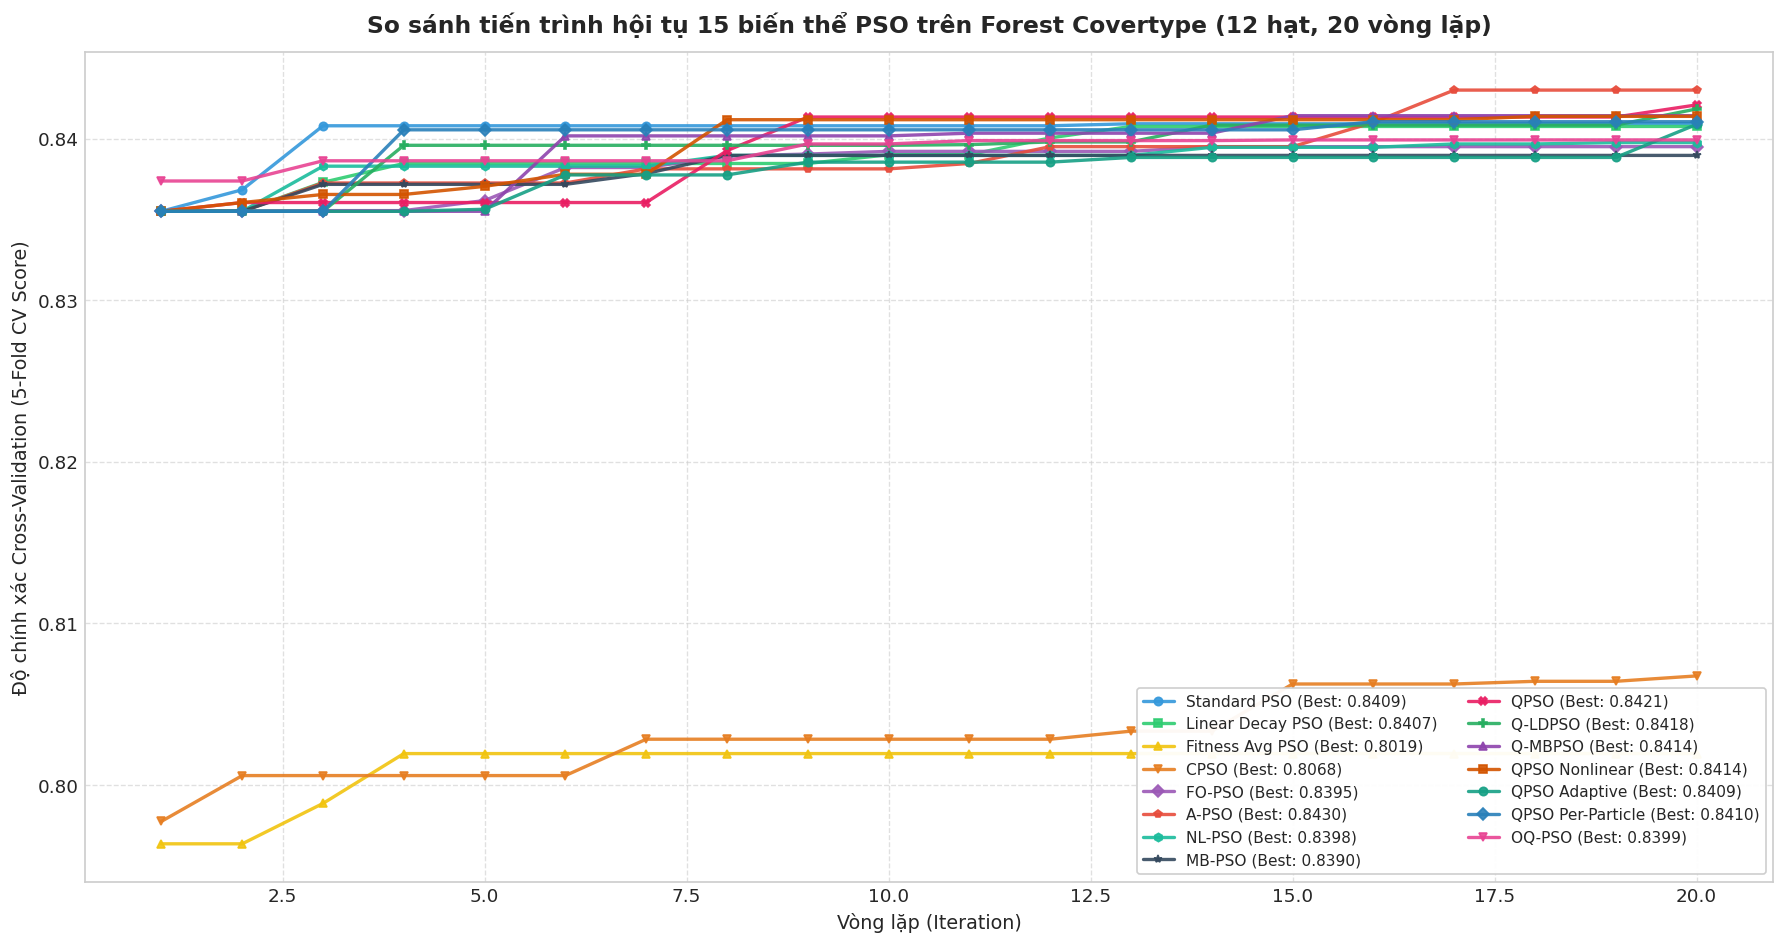

In [76]:
# So sánh đồ thị hội tụ của cả 15 biến thể PSO trên Forest Covertype
plt.figure(figsize=(15, 8))

algorithms = [
    ('Standard PSO', conv_std, '#3498db', 'o'),
    ('Linear Decay PSO', conv_ld, '#2ecc71', 's'),
    ('Fitness Avg PSO', conv_fa, '#f1c40f', '^'),
    ('CPSO', conv_cp, '#e67e22', 'v'),
    ('FO-PSO', conv_fo, '#9b59b6', 'D'),
    ('A-PSO', conv_apso, '#e74c3c', 'p'),
    ('NL-PSO', conv_nl, '#1abc9c', 'h'),
    ('MB-PSO', conv_mb, '#34495e', '*'),
    ('QPSO', conv_qpso, '#e91e63', 'X'),
    ('Q-LDPSO', conv_qld, '#27ae60', 'P'),
    ('Q-MBPSO', conv_qmb, '#8e44ad', '^'),
    ('QPSO Nonlinear', conv_qpso_nl, '#d35400', 's'),
    ('QPSO Adaptive', conv_qpso_ad, '#16a085', 'o'),
    ('QPSO Per-Particle', conv_qpso_pp, '#2980b9', 'D'),
    ('OQ-PSO', conv_oqpso, '#e84393', 'v')
]

for name, conv, color, marker in algorithms:
    if len(conv) > 0:
        plt.plot(range(1, len(conv) + 1), conv, 
                 label=f'{name} (Best: {conv[-1]:.4f})', 
                 color=color, marker=marker, markersize=5, linewidth=2, alpha=0.9)

plt.title('So sánh tiến trình hội tụ 15 biến thể PSO trên Forest Covertype (12 hạt, 20 vòng lặp)', fontsize=14, fontweight='bold', pad=12)
plt.xlabel('Vòng lặp (Iteration)', fontsize=11.5)
plt.ylabel('Độ chính xác Cross-Validation (5-Fold CV Score)', fontsize=11.5)
plt.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.95, fontsize=9.2, ncol=2)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

os.makedirs('../results/figures', exist_ok=True)
plt.savefig('../results/figures/chart_convergence_comparison_15algos.png', dpi=300, bbox_inches='tight')
plt.show()